---
title: "Al-Dahhan–Duduković high-pressure catalyst wetting efficiency in trickle beds"
description: "Eq. 9 of Al-Dahhan and Dudukovic, evaluated at the paper's own measured pressure drops, set against the 37 wetting efficiencies it was fitted to: the printed mean error, the band, the residual structure by bed and pressure drop, and the tracer-moment relations behind the data."
categories: [sec:G, struct:S3, tier:T1, data:tier4, phase:gas-liquid-solid]
date: 2026-11-28
---

# Al-Dahhan–Duduković high-pressure catalyst wetting efficiency in trickle beds

**Catalog ID:** `G1.5` · **Structures:** `S3` (pellet moment BVP) + algebraic closures · **Tier:** T1

Al-Dahhan and Dudukovic (Chem. Eng. Sci. 50 (1995) 2377-2389) measured the
liquid-catalyst contacting (wetting) efficiency of a bed of spheres and a bed of
extrudates with hexane and nitrogen at 0.31 to 4.93 MPa, and fitted eq. 9, which
raises wetting with the dimensionless pressure drop. They state "The mean relative
error is 3.7%." and "The data are bounded by ± 10%." (p. 2386). This page reads the
paper's own figures (the wetting efficiencies paired with their measured pressure
drops, the parity plot and the trend figure), evaluates eq. 9 with its printed
constants, and asks whether it reproduces those numbers and whether its residuals
are free of structure. It also solves, with pymrm, the pellet moment problem behind
the tracer method that produced the data. The wetting part is closed forms and
least squares; pymrm enters only in the moment problem.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "G1.5-al-dahhan-dudukovic-high-pressure-wetting"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The wetting part is algebra and least squares (numpy, scipy); pymrm solves
# the pellet moment problem of R6 (model.pellet_moment_coef) and measures its orders.
import re
from dataclasses import dataclass, replace
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import linear_sum_assignment
import pymrm
from pymrm.checks import observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
import model as M_
from model import (G_GRAV, FILM_EXACT, MOMENT_EXACT, cluster_bootstrap, d_volume, de_recovered,
                   deq_surface, design_bed, design_eq6, deviations, eq1_exponents, eta1, eta9,
                   eta9_reduced, ga9, gas_flux_ideal, half_units, interp_linear, interp_loglog, k9,
                   l_full9, leave_one_out, mean_se, metrics, ols, pellet_moment_coef, psi_l,
                   psig_to_mpa, re9, rho_implied, shape_factor, tracer_standard, tracer_table2)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``; ``pctN`` shows a fraction as a
    percentage with N decimals."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        x = v[name]
        mp = re.fullmatch(r"(\+?)pct(\d+)", fmt)
        if mp:
            return f"{x * 100:{mp.group(1)}.{mp.group(2)}f} %"
        return format(x, fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))


def below(x, b):
    """A round-off-level number printed as its bound, so the text is the same on every BLAS kernel."""
    return f"below {b:.0e}" if x < b else f"{x:.1e}"


def above(x, b):
    return f"above {b:.0e}" if x > b else f"{x:.1e}"

## Background

In a trickle bed the liquid may cover only part of the external catalyst surface.
The contacting efficiency $\eta_{CE}$ (wetted fraction of the external area) enters
every rate model of a partially wetted pellet (page
[G1.8](../G1.8-trickle-bed-partial-wetting/) consumes one). Industrial beds run at
high pressure, where most correlations were never tested. Al-Dahhan and Dudukovic
argue from Holub's slit model (their eqs. 3 to 5, p. 2379) that at a fixed liquid
rate a larger dimensionless pressure drop, from gas velocity or gas density, thins the
film but spreads it, so wetting rises. They assume $\eta_{CE} \propto
(\psi_L/Ga_L)^m$, write the general form eq. 6 (p. 2380) and fit eq. 9 (p. 2386) to
tracer-measured wetting efficiencies of two beds at 0.31, 3.55 and 4.93 MPa (their
Figs 4a and 5a), with the measured pressure drops beside them (Figs 4b, 5b).

**The question this page tests.** Does eq. 9 with its printed constants, evaluated at
the paper's own measured pressure drops and the Table 4 beds, reproduce the
measured wetting efficiencies of Figs 4a and 5a to the printed accuracy (mean relative error 3.7 %,
every point within ±10 %), and are its residuals free of the structure (bed, pressure
drop) that its single exponent on $\psi_L/Ga_L$ is meant to carry? The figures decide
it: one pixel at 300 ppi is a small fraction of a per cent in $\eta_{CE}$ (the
sidecars give the calibration), far finer than the claims, and the liquid properties, which the paper does not print, enter eq. 9
only as $(\mu_L\rho_L^2)^{-1/9}$.

Not covered here: the holdup panels (Figs 4c, 5c), Holub's eqs. 3 to 5 (their algebra
only), the flow map of Fig. 3, eq. 2, and every statement about El-Hisnawi's own
data. Pressure drop and holdup at pressure are the subject of page
[G1.7](../G1.7-wammes-high-pressure-trickle-bed/); this page uses the measured pressure
drops, no pressure-drop correlation.

## The published model

| | equation as used | source |
|---|---|---|
| eq. 9 | $\eta_{CE} = 1.104\,Re_L^{1/3}\left[\dfrac{1 + (\Delta P/Z)/(\rho_L g)}{Ga_L}\right]^{1/9}$, $Re_L = \dfrac{U_L\rho_L d_p}{\mu_L(1-\varepsilon_B)}$, $Ga_L = \dfrac{d_p^3\rho_L^2 g\,\varepsilon_B^3}{\mu_L^2(1-\varepsilon_B)^3}$ | p. 2386 and abstract (p. 2377) |
| eq. 6 | $\eta_{CE} = c\,Re_L^{n}\,(\psi_L/Ga_L)^{m}$, $\psi_L = 1 + (\Delta P/Z)/(\rho_L g)$ | p. 2380 |
| eq. 1 | $\eta_{CE} = 1.617\,Re_L^{0.1461}\,Ga_L^{-0.0711}$, $Re_L = L d_p/\mu_L$, $Ga_L = d_p^3 g\rho_L^2/\mu_L^2$ (no voidage) | El-Hisnawi, p. 2378 |
| eq. 8 | $\eta_{CE} = (D_{e,TF}/D_{e,LF})^{1/2}$ from tracer variances (Tables 1, 2) | pp. 2382-2383 |

Written out (a reduction the paper does not print), eq. 9 is
$\eta_{CE} = K\,L^{1/3}\varepsilon_B^{-1/3}\psi_L^{1/9}$ with
$K = 1.104\,(\mu_L\rho_L^2 g)^{-1/9}$: because the exponent of $Re_L$ is three times
that of $\psi_L/Ga_L$, the particle diameter and $(1-\varepsilon_B)$ cancel exactly.
Eq. 9 therefore has no particle-size dependence; the bed enters only as
$\varepsilon_B^{-1/3}$. Eq. 1 keeps $d_p^{-0.0672}$.

| symbol | code | unit |
|---|---|---|
| $L = U_L\rho_L$ | `L` | kg/(m² s) |
| $(\Delta P/Z)/(\rho_L g)$ | `dpz` | - |
| $\psi_L$ | `psi_l(dpz)` | - |
| $d_p$, $\varepsilon_B$ | `d_p`, `eps_B` | m, - |
| $\rho_L$, $\mu_L$ | `rho`, `mu` | kg/m³, Pa s |
| printed constants | `K["c9"]`, `K["n9"]`, `K["m9"]`, `K["c1"]`, `K["n1"]`, `K["m1"]` | - |

Deviation is $(p - e)/e$ (prediction against experiment) unless said otherwise; the
page also reports $(p-e)/p$, and every metric both with predictions capped at 1 (a
wetted fraction cannot exceed 1) and uncapped, because the paper says neither.

## Parameters and assumptions

Every printed number is read from the page images into
`al-dahhan-1995-printed-numbers.csv` (strings, compared in half-units of the last
printed digit). The beds are those of Table 4: spheres $d_p$ = 0.152 cm,
$\varepsilon_B$ = 0.412; extrudates 0.157 cm x 0.43 cm with the printed
$(d_p)_{eq}$ = 0.199 cm, which is the surface-volume diameter $6V_p/S_{ex}$ (V2), and
$\varepsilon_B$ = 0.355. Eq. 9 does not depend on $d_p$, so only eq. 1 uses it.

The paper prints no liquid property; its liquid is "commercial grade hexane". The page
takes pure n-hexane at 298 K from the NIST Chemistry WebBook (an external input, in
`nist-n-hexane-298k.csv`) at 0.31 MPa for every point, and reports the effect of
taking it at each case's pressure as a sensitivity. Gravity is 9.80665 m/s². The
nitrogen dissolved in the liquid at pressure is not represented.

In [3]:
PN = load_data("al-dahhan-1995-printed-numbers.csv", page=PAGE, dtype=str).set_index("name")["printed"]


def num(s):
    """A printed number as a float; fractions as printed ('1/3')."""
    return float(Fraction(s)) if "/" in s else float(s)


K = {k: num(PN[k]) for k in ("c9", "n9", "m9", "c1", "n1", "m1")}
PROPS = load_data("nist-n-hexane-298k.csv", page=PAGE)
print(cite_data(load_meta("nist-n-hexane-298k.csv", page=PAGE)))
CM = 1e-2   # m per cm
BEDS = {"sphere": {"d_p": num(PN["sph_dp_cm"]) * CM, "eps_B": num(PN["sph_eps_b"])},
        "extrudate": {"d_p": deq_surface(num(PN["ext_d_cm"]), num(PN["ext_l_cm"])) * CM,
                      "eps_B": num(PN["ext_eps_b"])}}
CASE_P = {"2": "0.31", "3": "0.31", "4": "3.55", "5": "3.55", "5b": "4.93"}   # MPa per legend case
print(K)
print({b: {k: round(v, 6) for k, v in d.items()} for b, d in BEDS.items()})
print(PROPS.to_string(index=False))

Lemmon, E. W.; Bell, I. H.; Huber, M. L.; McLinden, M. O. (2026) — Thermophysical Properties of Fluid Systems, NIST Chemistry WebBook, NIST Standard Reference Database 69 (eds. P. J. Linstrom and W. G. Mallard) — doi:10.18434/T4D303 — transcribed
{'c9': 1.104, 'n9': 0.3333333333333333, 'm9': 0.1111111111111111, 'c1': 1.617, 'n1': 0.1461, 'm1': -0.0711}
{'sphere': {'d_p': 0.00152, 'eps_B': 0.412}, 'extrudate': {'d_p': 0.001991, 'eps_B': 0.355}}
   p_MPa   T_K  rho_kg_m3  mu_Pa_s
0.101325 298.0    654.990 0.000298
0.310000 298.0    655.222 0.000299
3.550000 298.0    658.718 0.000310
4.930000 298.0    660.154 0.000314


## The data

All data are digitised from the publisher's 300 ppi scan by `data/digitise.py`; each
CSV has a sidecar with the tick pixels, the calibration residuals, marker shape per
case and the reading SD of every point. Figs 4a, 5a and 7 have logarithmic axes
although their tick labels read linear (ticks 0.5 to 1.0 are spaced as
$\ln\eta$); Figs 4b, 5b and 6 are linear. Calibrating a log axis as linear is the
likeliest digitising defect, and the break table carries it as a row.

Each wetting point is paired with the pressure-drop point of the same case and rank in
$L$; $L$ is taken from panel (a). Four points (two per bed) sit on the
$\eta_{CE}$ = 1 frame: whether they were measured as 1 or clipped by the frame is not
said; refits are shown without and with them.

In [4]:
F4 = load_data("al-dahhan-1995-fig4.csv", page=PAGE, dtype={"case": str})
F5 = load_data("al-dahhan-1995-fig5.csv", page=PAGE, dtype={"case": str})
F6 = load_data("al-dahhan-1995-fig6.csv", page=PAGE)
F7 = load_data("al-dahhan-1995-fig7.csv", page=PAGE)
for f in ("al-dahhan-1995-fig4.csv", "al-dahhan-1995-fig6.csv"):
    print(cite_data(load_meta(f, page=PAGE)))
F4.flag, F5.flag, F6.flag, F7.flag = (f.flag.fillna("") for f in (F4, F5, F6, F7))
say("Read from the scan: Fig. 4 (spheres) <<a4:d>> wetting efficiencies and <<b4:d>> pressure drops, <<c1:d>> of them "
    "case 1 (no gas) on the zero axis and not used; Fig. 5 (extrudates, with the 4.93 MPa series called case 5b here) "
    "<<a5:d>> and <<b5:d>>; Fig. 6 <<r6:d>> rings resolved, of which <<cs:d>> in a stack at (1, 1) that may hide one more; "
    "Fig. 7 <<m7:d>> markers and the two predicted lines (<<l7:d>> line points).",
    a4=int((F4.panel == "a").sum()), b4=int((F4.panel == "b").sum()), c1=int(((F4.panel == "b") & (F4.case == "1")).sum()),
    a5=int((F5.panel == "a").sum()), b5=int((F5.panel == "b").sum()), r6=len(F6),
    cs=int(F6.flag.str.contains("corner").sum()), m7=int((F7.kind == "marker").sum()), l7=int((F7.kind == "line").sum()))


@dataclass(frozen=True)
class Inputs:
    """The data and every switch a break-table row can flip."""
    f4: pd.DataFrame
    f5: pd.DataFrame
    f6: pd.DataFrame
    f7: pd.DataFrame
    beds: dict
    props: pd.DataFrame
    cap: bool = True               # predictions capped at 1 in the "capped" metrics
    voidage: bool = True           # eq. 9 groups with the voidage terms
    one_plus: bool = True          # psi_L = 1 + dpz
    pair_shift: bool = False       # pressure drop taken from the neighbouring case
    linear_4a: bool = False        # Fig. 4a calibrated linear
    linear_7: bool = False         # Fig. 7 calibrated linear
    eq1_voidage: bool = False      # eq. 1 with the voidage groups of eq. 9
    refit: str = "bed"             # within-bed exponents from the bed-offset form
    interp: str = "loglog"         # E10 interpolation
    nu_sphere: int = 2             # construct_div geometry of the sphere
    film: str = "robin"            # the film condition of the BVP
    weight: str = "volume"         # volume average weights
    factor2: bool = True           # 2 in the second cumulant
    sd_scale: float = 1.0          # reading SDs
    atm: float = 0.101325          # MPa added to gauge pressure
    deq: str = "surface"           # equivalent diameter tested against 0.199
    t_gas: float = 298.0           # K, ideal N2 density
    dtype: type = float            # precision of the BVP solves
    swap_reactors: bool = False    # reactor diameters swapped between the beds
    cluster_by: str = "case"       # bootstrap resamples (bed, case) clusters


C0 = Inputs(F4, F5, F6, F7, BEDS, PROPS)

Al-Dahhan, M. H.; Dudukovic, M. P. (1995) — Chemical Engineering Science 50(15), 2377-2389 — doi:10.1016/0009-2509(95)00092-J — digitised from Fig. 4 (a) and (b), journal p. 2385 (PDF page 9)
Al-Dahhan, M. H.; Dudukovic, M. P. (1995) — Chemical Engineering Science 50(15), 2377-2389 — doi:10.1016/0009-2509(95)00092-J — digitised from Fig. 6, journal p. 2387 (PDF page 11)


Read from the scan: Fig. 4 (spheres) 17 wetting efficiencies and 22 pressure drops, 5 of them case 1 (no gas) on the zero axis and not used; Fig. 5 (extrudates, with the 4.93 MPa series called case 5b here) 20 and 20; Fig. 6 33 rings resolved, of which 3 in a stack at (1, 1) that may hide one more; Fig. 7 7 markers and the two predicted lines (19 line points).

## PyMRM implementation

Eq. 9, eq. 1, the metrics and the refits are closed forms and linear least squares in
logarithms (`model.py`); pymrm adds nothing there. The tracer method of eq. 8 turns the
variance of a tracer response into an effective diffusivity through the pellet's
first-moment coefficient: $\tau_1 = c\,\varepsilon_p R^2/D_e$, with $c$ = 1/15
(sphere), 1/8 (infinite cylinder), 1/3 (slab), plus a film term $c_f/Bi$
($c_f$ = 1/3, 1/2, 1). The page computes $c$ as minus the volume average of $u$ in

$$\frac{1}{x^\nu}\frac{d}{dx}\left(x^\nu\frac{du}{dx}\right) = 1,\quad
\frac{du}{dx}(0) = 0,\quad u(1) = 0\ \text{or}\ \frac{du}{dx}(1) + Bi\,u(1) = 0,$$

discretised with `construct_grad` and `construct_div` (`nu` = 2, 1, 0) on uniform cells,
solved with one sparse direct solve, and averaged with the exact cell volumes
(differences of $x^{\nu+1}$). `observed_orders` measures the order on 40 to 320 cells
and gives the Richardson value. The boundary conditions as pymrm reads them:

In [5]:
_xf = np.linspace(0.0, 1.0, 5)
print(pymrm.describe_bc(({"a": 1, "b": 0, "d": 0}, {"a": 1, "b": 5.0, "d": 0}), _xf))

lower (x=0, outward normal -x): -1*dc/dx + 0*c = 0  [Neumann]
upper (x=1, outward normal +x): 1*dc/dx + 5*c = 0  [Robin]


### The check values

Before any result, the page's functions reproduce 65 values computed by a second route
(a separate script, numpy, scipy and mpmath, no page code) at a stated test condition:
eq. 9 full groups against the reduced form, the full-wetting $L$, eq. 1, the metric
conventions on a synthetic set, the Table 3 and 4 input checks, the moment
coefficients and the tracer moments. The test properties (654.8 kg/m³, 0.300 mPa s)
are test inputs only.

In [6]:
def check_computed(K):
    """The page's value for every row of data/check_values.csv."""
    rho, mu, L, dpz = 654.8, 3.0e-4, 1.0, 0.5
    ds, es = 1.52e-3, 0.412
    dx, ex = deq_surface(1.57e-3, 4.3e-3), 0.355
    c = {"re9_sphere": re9(L, ds, es, mu), "ga9_sphere": ga9(ds, es, rho, mu),
         "eta9_sphere": eta9(L, dpz, ds, es, rho, mu, K), "k9_prefactor_si": k9(rho, mu, K),
         "eta9_extrudate": eta9(L, dpz, dx, ex, rho, mu, K),
         "eta9_sphere_psi1": eta9(L, 0.0, ds, es, rho, mu, K),
         "eta9_capped_sphere_L2_dpz4": eta9(2.0, 4.0, ds, es, rho, mu, K),
         "eta9_uncapped_sphere_L2_dpz4": eta9(2.0, 4.0, ds, es, rho, mu, K, cap=False),
         "lfull_sphere": l_full9(dpz, ds, es, rho, mu, K),
         "re1_sphere": L * ds / mu, "ga1_sphere": ds ** 3 * G_GRAV * rho ** 2 / mu ** 2,
         "eta1_sphere": eta1(L, ds, rho, mu, K), "eta1_extrudate": eta1(L, dx, rho, mu, K)}
    c["eta9_ratio_extrudate_over_sphere"] = c["eta9_extrudate"] / c["eta9_sphere"]
    c["eta9_ratio_dp_doubled"] = eta9(L, dpz, 2 * ds, es, rho, mu, K) / c["eta9_sphere"]
    c["eta9_psi1_over_eta1_sphere"] = c["eta9_sphere_psi1"] / c["eta1_sphere"]
    c["eq1_dp_exponent"], c["eq1_mu_exponent"] = eq1_exponents(K)
    synth = [(1.0, 0.5, 0.70, ds, es), (2.0, 4.0, 0.98, ds, es), (0.7, 3.0, 0.66, dx, ex), (1.5, 0.1, 0.85, dx, ex)]
    e = np.array([s[2] for s in synth])
    for cap, cn in ((True, "capped"), (False, "uncapped")):
        p = np.array([eta9(a, b, d, eb, rho, mu, K, cap=cap) for a, b, _, d, eb in synth])
        for conv in ("exp", "pred"):
            m = metrics(p, e, conv)
            c[f"synth_mre_{cn}_{conv}"], c[f"synth_maxdev_{cn}_{conv}"] = m["mre"], m["maxdev"]
            c[f"synth_inside10_{cn}_{conv}"] = m["inside"]
    c["deq_extrudate_cm"] = deq_surface(0.157, 0.43)
    c["deq_halfunits_vs_0p199"] = half_units(c["deq_extrudate_cm"], "0.199")
    c["dvol_extrudate_cm"], c["shape_factor_Sr_over_2V"] = d_volume(0.157, 0.43), shape_factor(0.157, 0.43)
    c["dr_over_dp_extrudate"], c["dr_over_dp_sphere"] = 2.19 / c["deq_extrudate_cm"], 2.22 / 0.152
    for ps, pr in ((30, "0.31"), (500, "3.55"), (700, "4.93")):
        c[f"p_abs_mpa_{ps}psig"] = psig_to_mpa(ps)
        c[f"p_halfunits_{ps}psig"] = half_units(psig_to_mpa(ps), pr)
    c["p_halfunits_700psig_vs_table3_5p0"] = half_units(psig_to_mpa(700), "5.0")
    c["gmax_ideal_4p93mpa_7p20cms"] = gas_flux_ideal(4.93, 7.20)
    c["gmin_ideal_0p31mpa_1cms"] = gas_flux_ideal(0.31, 1.0)
    c["gmin_ratio_expected_over_printed"] = c["gmin_ideal_0p31mpa_1cms"] / 6.64e-3
    for nm, dr in (("ss", 0.0219), ("acrylic", 0.0222)):
        c[f"rhoL_implied_Lmax_Qmax_{nm}"] = rho_implied(2.7, 93, dr)
        c[f"rhoL_implied_Lmin_Qmin_{nm}"] = rho_implied(0.42, 15, dr)
    for nu, nm in ((2, "sphere"), (1, "cylinder"), (0, "slab")):
        c[f"tau1_coef_{nm}"] = MOMENT_EXACT[nu]
    c["tau1_coef_sphere_film_bi5"] = MOMENT_EXACT[2] + FILM_EXACT[2] / 5
    c["tau1_coef_cylinder_film_bi5"] = MOMENT_EXACT[1] + FILM_EXACT[1] / 5
    c |= tracer_t2()
    return c


def tracer_t2(factor2=True):
    """The tracer rows at condition T2 (sphere bed of Table 4, Q_L 50 ml/min, assumed
    De_LF 1.0e-9 and De_TF 0.64e-9 m2/s, eps_L 0.15, plug flow, no film)."""
    es, ep, R = 0.412, 0.697, 0.76e-3
    Vr, Q = np.pi * 0.0222 ** 2 / 4 * 0.5163, 50e-6 / 60
    mu1, var, sig = tracer_standard(Vr, es, es, ep, R, 1e-9, Q, factor2=factor2)
    s2, slope = tracer_table2(Vr, es, es, ep, R, 1e-9, Q)
    sig_tf = tracer_standard(Vr, 0.15, es, ep, R, 0.64e-9, Q, factor2=factor2)[2]
    lf_h = de_recovered(sig, Vr, es, es, ep, R, Q)
    tf_h = de_recovered(sig_tf, Vr, 0.15, es, ep, R, Q)
    tf_s = de_recovered(sig_tf, Vr, 0.15, es, ep, R, Q, form="standard", factor2=factor2)
    return {"tracer_mu1_lf_s": mu1, "tracer_var_lf_standard_s2": var, "tracer_sigD2_lf_standard": sig,
            "tracer_sigD2_lf_table2": s2, "tracer_table2_over_standard": s2 / sig,
            "tracer_slope_lf_table2_s_per_m3": slope, "tracer_de_lf_recovered_over_true": lf_h / 1e-9,
            "tracer_eta_ce_same_convention": np.sqrt(tf_h / lf_h),
            "tracer_eta_ce_mixed_over_true": np.sqrt(tf_s / lf_h) / 0.8,
            "tracer_mu1_tf_s": tracer_standard(Vr, 0.15, es, ep, R, 0.64e-9, Q)[0],
            "_slope_q_gap": abs(slope * Q / s2 - 1.0)}


CHECK_DEV = assert_check_values({k: v for k, v in check_computed(K).items() if not k.startswith("_")}, page=PAGE)

check values: 65 of 65 agree, worst relative 4.1e-12


### The study

One function computes every number the page reports from the printed constants `K`
and the inputs `C`; the break table reruns it with one defect at a time.

In [7]:
SEED, N_MC, N_BOOT = 20261128, 2000, 2000
FRAC_SD = 2.0           # "decided" means farther than 2 reading SDs from a threshold


def props_at(C, p):
    """(rho, mu) of the liquid at pressure p (MPa string or float) from the property table."""
    row = C.props.iloc[(C.props.p_MPa - float(p)).abs().argsort().iloc[0]]
    return float(row.rho_kg_m3), float(row.mu_Pa_s)


def relinear(px, val, lo, hi):
    """The linear-axis defect: a log axis read as linear through its two end ticks lo, hi.
    ln(val) is affine in px on the log axis; the end-tick pixels follow from that fit."""
    b, a = np.polyfit(px, np.log(val), 1)
    p_lo, p_hi = (np.log(lo) - a) / b, (np.log(hi) - a) / b
    return lo + (hi - lo) * (np.asarray(px) - p_lo) / (p_hi - p_lo)


def points(C):
    """The 37 paired points: bed, case, L (panel a), eta, dpz (panel b) and reading SDs."""
    rows = []
    for bed, f in (("sphere", C.f4), ("extrudate", C.f5)):
        a, b = f[f.panel == "a"].copy(), f[(f.panel == "b") & (f.case != "1")]
        if bed == "sphere" and C.linear_4a:
            a["L_kg_m2s"] = relinear(a.px_x, a.L_kg_m2s, 0.5, 3.0)
            a["value"] = relinear(a.px_y, a.value, 0.5, 1.0)
        partner = {"2": "3", "3": "2", "4": "5", "5": "4", "5b": "5"}
        for case in sorted(a.case.unique()):
            ca = a[a.case == case].sort_values("L_kg_m2s")
            cb = b[b.case == case].sort_values("L_kg_m2s")
            if len(ca) != len(cb):
                raise ValueError(f"{bed} case {case}: {len(ca)} wetting and {len(cb)} pressure-drop points")
            for (_, ra), (_, rb) in zip(ca.iterrows(), cb.iterrows()):
                dpz, sd_dpz = rb.value, rb.sd_value
                if C.pair_shift:
                    q = b[b.case == partner[case]]
                    j = (q.L_kg_m2s - ra.L_kg_m2s).abs().argsort().iloc[0]
                    dpz = q.value.iloc[j]
                rows.append(dict(bed=bed, case=case, cluster=f"{bed} {case}", L=ra.L_kg_m2s, eta=ra.value,
                                 dpz=dpz, L_b=rb.L_kg_m2s, sd_L=ra.sd_L * C.sd_scale,
                                 sd_eta=ra.sd_value * C.sd_scale, sd_dpz=sd_dpz * C.sd_scale,
                                 frame="frame" in ra.flag))
    return pd.DataFrame(rows)


def pred9(P, C, K, cap, props=None, L=None, dpz=None):
    """Eq. 9 at the points P (or at arrays L, dpz of their shape broadcast over draws),
    liquid properties at 0.31 MPa or per case."""
    dp = np.array([C.beds[b]["d_p"] for b in P.bed])
    eb = np.array([C.beds[b]["eps_B"] for b in P.bed])
    if props == "case":
        rho, mu = np.array([props_at(C, CASE_P[c]) for c in P.case]).T
    else:
        rho, mu = props_at(C, "0.31")
    return eta9(P.L.to_numpy() if L is None else L, P.dpz.to_numpy() if dpz is None else dpz,
                dp, eb, rho, mu, K, cap=cap, voidage=C.voidage, one_plus=C.one_plus)


def dev_sd(P, pred, K):
    """Reading SD of each deviation (p - e)/e: eta, and L and dpz through eq. 9's
    exponents where the prediction is below 1."""
    live = pred < 1.0
    s2 = P.sd_eta ** 2 + live * ((K["n9"] * P.sd_L) ** 2 + (K["m9"] * P.sd_dpz / psi_l(P.dpz)) ** 2)
    return (pred / P.eta) * np.sqrt(s2)


def r1(C, K):
    """Eq. 9 against eq. 1 and the bed and particle-size terms, n-hexane at 0.31 MPa."""
    rho, mu = props_at(C, "0.31")
    s, x = C.beds["sphere"], C.beds["extrudate"]
    e9 = lambda L, dpz, b, **kw: eta9(L, dpz, b["d_p"], b["eps_B"], rho, mu, K, cap=False,
                                       voidage=C.voidage, one_plus=C.one_plus, **kw)
    e1 = lambda L, b: eta1(L, b["d_p"], rho, mu, K, eps_B=b["eps_B"] if C.eq1_voidage else None)
    Ls = np.geomspace(0.4, 2.8, 60)
    red = eta9_reduced(Ls, 0.5, s["eps_B"], rho, mu, K)
    return {"r1_ext_over_sph_eq9": e9(1.0, 0.5, x) / e9(1.0, 0.5, s),
            "r1_ext_over_sph_eq1": e1(1.0, x) / e1(1.0, s),
            "r1_eq9_over_eq1_sph_psi1": e9(1.0, 0.0, s) / e1(1.0, s),
            "r1_eq9_over_eq1_ext_psi1": e9(1.0, 0.0, x) / e1(1.0, x),
            "r1_dp_doubled_gap": abs(e9(1.0, 0.5, dict(s, d_p=2 * s["d_p"])) / e9(1.0, 0.5, s) - 1.0),
            "r1_reduced_gap": float(np.max(np.abs(e9(Ls, 0.5, s) / red - 1.0))),
            "r1_lfull_sph_psi1": l_full9(0.0, s["d_p"], s["eps_B"], rho, mu, K),
            "r1_eta9_sph_L1_psi1": e9(1.0, 0.0, s),
            "_Ls": Ls, "_e9s": e9(Ls, 0.0, s), "_e9x": e9(Ls, 0.0, x), "_e1s": e1(Ls, s), "_e1x": e1(Ls, x)}


def r2(C, K, P, rng):
    """Route A: eq. 9 at the 37 paired points."""
    out = {}
    pc, pu = pred9(P, C, K, cap=C.cap), pred9(P, C, K, cap=False)
    for tag, p in (("capped", pc), ("uncapped", pu)):
        for conv in ("exp", "pred"):
            m = metrics(p, P.eta, conv)
            out[f"r2_mre_{tag}_{conv}"], out[f"r2_maxdev_{tag}_{conv}"] = m["mre"], m["maxdev"]
            out[f"r2_inside_{tag}_{conv}"], out[f"r2_inside_{tag}_{conv}__margin"] = m["inside"], m["margin"]
    d = deviations(pc, P.eta)
    sd = dev_sd(P, pc, K)
    out["r2_n_certain_inside"] = int(np.sum(np.abs(d) + FRAC_SD * sd <= 0.10))
    out["r2_maxdev_plus_2sd"] = float(np.max(np.abs(d) + FRAC_SD * sd))
    out["r2_n_pred_above_1"] = int(np.sum(pu > 1.0))
    out["r2_n_pred_above_1__margin"] = float(np.min(np.abs(pu - 1.0)))
    du = deviations(pu, P.eta)
    iu = int(np.argmax(np.abs(du)))
    out["r2_uncapped_worst_L"], out["r2_uncapped_worst_dev"] = float(P.L.iloc[iu]), float(du[iu])
    out["r2_mre_case_props"] = metrics(pred9(P, C, K, cap=C.cap, props="case"), P.eta)["mre"]
    # reading-error Monte Carlo of the capped (p - e)/e MRE
    z = rng.normal(0.0, 1.0, (3, N_MC, len(P)))
    e_mc = P.eta.to_numpy() * np.exp(z[1] * P.sd_eta.to_numpy())
    p_mc = pred9(P, C, K, cap=C.cap, L=P.L.to_numpy() * np.exp(z[0] * P.sd_L.to_numpy()),
                 dpz=P.dpz.to_numpy() + z[2] * P.sd_dpz.to_numpy())
    mre = np.mean(np.abs(p_mc / e_mc - 1.0), axis=1)
    out["r2_mc_sd"] = float(mre.std(ddof=1))
    out["_pc"], out["_pu"], out["_dev"], out["_sd"] = pc, pu, d, sd
    return out


def match_rings(C, K, P, pc):
    """Assign each Fig. 6 ring to a measured point by eta_exp (least squares assignment)."""
    f6 = C.f6
    cost = (f6.eta_exp.to_numpy()[:, None] - P.eta.to_numpy()[None, :]) ** 2
    ri, pj = linear_sum_assignment(cost)
    srt = np.sort(np.abs(f6.eta_exp.to_numpy()[:, None] - P.eta.to_numpy()[None, :]), axis=1)
    tol = FRAC_SD * np.hypot(f6.sd_exp.to_numpy(), np.median(P.sd_eta * P.eta))
    ambiguous = (srt[:, 1] - srt[:, 0]) < tol
    return ri, pj, ambiguous


def r3(C, K, P, pc, rng):
    """Route B: the paper's own parity plot (Fig. 6) and trend figure (Fig. 7)."""
    out = {}
    f6, f7 = C.f6, C.f7
    m = metrics(f6.eta_pred, f6.eta_exp, "exp")
    out["r3_n_rings"] = len(f6)
    out["r3_mre_B"], out["r3_maxdev_B"] = m["mre"], m["maxdev"]
    out["r3_inside_B"], out["r3_inside_B__margin"] = m["inside"], m["margin"]
    out["r3_mre_B_pred"] = metrics(f6.eta_pred, f6.eta_exp, "pred")["mre"]
    n_exp = len(P)
    out["r3_mre_B_37"] = m["mre"] * len(f6) / n_exp          # missing rings at zero deviation
    z = rng.normal(0.0, 1.0, (2, N_MC, len(f6)))
    p_mc = f6.eta_pred.to_numpy() + z[0] * f6.sd_pred.to_numpy() * C.sd_scale
    e_mc = f6.eta_exp.to_numpy() + z[1] * f6.sd_exp.to_numpy() * C.sd_scale
    mre = np.mean(np.abs(p_mc / e_mc - 1.0), axis=1)
    out["r3_mc_sd"] = float(mre.std(ddof=1))
    out["r3_n_pred_above_1"] = int(np.sum(f6.eta_pred > 1.0 + FRAC_SD * f6.sd_pred))
    ri, pj, amb = match_rings(C, K, P, pc)
    ratio = f6.eta_pred.to_numpy()[ri] / pc[pj]
    live = (f6.eta_pred.to_numpy()[ri] < 0.985) & (pc[pj] < 0.985)
    out["r3_n_ambiguous"] = int(amb[ri].sum())
    for bed in ("sphere", "extrudate"):
        sel = live & (P.bed.to_numpy()[pj] == bed)
        out[f"r3_ratio_{bed}"], out[f"r3_ratio_{bed}_se"] = mean_se(ratio[sel])
        out[f"r3_ratio_{bed}_n"] = int(sel.sum())
    out["r3_ratio_pooled"] = float(np.mean(ratio[live]))
    out["_ring_ratio"], out["_ring_bed"], out["_ring_live"] = ratio, P.bed.to_numpy()[pj], live
    # Fig. 7: lines and markers against eq. 9 at the Fig. 5b pressure drops
    g = f7.copy()
    if C.linear_7:
        g["L_kg_m2s"] = relinear(g.px_x, g.L_kg_m2s, 0.5, 3.0)
        g["eta_CE"] = relinear(g.px_y, g.eta_CE, 0.6, 1.0)
    rho, mu = props_at(C, "0.31")
    x = C.beds["extrudate"]
    b5 = C.f5[(C.f5.panel == "b")]
    for tag, case, series in (("solid", "2", "pred 0.31 MPa"), ("dashed", "5", "pred 3.55 MPa")):
        ln = g[(g.kind == "line") & (g.series == series)]
        bb = b5[b5.case == case].sort_values("L_kg_m2s")
        # pressure drop of the case at the line's L: a named data interpolation, clamped at the ends
        dpz = np.interp(ln.L_kg_m2s, bb.L_kg_m2s, bb.value)
        e9 = eta9(ln.L_kg_m2s.to_numpy(), dpz, x["d_p"], x["eps_B"], rho, mu, K, cap=False,
                  voidage=C.voidage, one_plus=C.one_plus)
        rt = ln.eta_CE.to_numpy() / e9
        out[f"r3_f7_{tag}_over_eq9"] = float(rt.mean())
        out[f"r3_f7_{tag}_over_eq9_spread"] = float(rt.max() - rt.min())
        out[f"r3_f7_{tag}_slope"] = float(np.polyfit(np.log(ln.L_kg_m2s), np.log(ln.eta_CE), 1)[0])
        out[f"r3_f7_{tag}_eq9_slope"] = float(np.polyfit(np.log(ln.L_kg_m2s), np.log(e9), 1)[0])
    a5 = C.f5[C.f5.panel == "a"]
    gaps_L, gaps_e = [], []
    for series, case in (("exp 0.31 MPa", "2"), ("exp 3.55 MPa", "5")):
        mk = g[(g.kind == "marker") & (g.series == series)]
        ref = a5[a5.case == case]
        for r in mk.itertuples():
            j = (np.log(ref.L_kg_m2s) - np.log(r.L_kg_m2s)).abs().argsort().iloc[0]
            gaps_L.append(r.L_kg_m2s / ref.L_kg_m2s.iloc[j] - 1)
            gaps_e.append(r.eta_CE / ref.value.iloc[j] - 1)
    out["v1_f7_vs_f5a_L_max"] = float(np.max(np.abs(gaps_L)))
    out["v1_f7_vs_f5a_eta_max"] = float(np.max(np.abs(gaps_e)))
    out["v1_f6_vs_points_eta_max"] = float(np.max(np.abs(f6.eta_exp.to_numpy()[ri][~amb[ri]] / P.eta.to_numpy()[pj][~amb[ri]] - 1)))
    return out


def r4(C, K, P, pc, rng):
    """What the residuals hold: bed split, refits, bootstrap, leave-one-case-out, gains."""
    out = {}
    d = deviations(pc, P.eta)
    for bed in ("sphere", "extrudate"):
        out[f"r4_bias_{bed}"], out[f"r4_bias_{bed}_se"] = mean_se(d[P.bed == bed])
    out["r4_bias_diff"] = out["r4_bias_extrudate"] - out["r4_bias_sphere"]
    out["r4_bias_diff_se"] = float(np.hypot(out["r4_bias_sphere_se"], out["r4_bias_extrudate_se"]))
    out["r4_bias_z"] = out["r4_bias_diff"] / out["r4_bias_diff_se"]
    rho, mu = props_at(C, "0.31")
    Q = P[~P.frame].reset_index(drop=True)
    dp = np.array([C.beds[b]["d_p"] for b in Q.bed])
    eb = np.array([C.beds[b]["eps_B"] for b in Q.bed])
    y = np.log(Q.eta.to_numpy())
    X6 = design_eq6(Q.L.to_numpy(), Q.dpz.to_numpy(), dp, eb, rho, mu)
    b6, s6 = ols(X6, y)
    out["r4_eq6_c"], out["r4_eq6_n"], out["r4_eq6_m"] = float(np.exp(b6[0])), float(b6[1]), float(b6[2])
    out["r4_eq6_n_se"], out["r4_eq6_m_se"] = float(s6[1]), float(s6[2])
    out["r4_eq6_m_dist_19_se"] = (K["m9"] - out["r4_eq6_m"]) / out["r4_eq6_m_se"]
    out["r4_eq6_n_dist_13_se"] = (K["n9"] - out["r4_eq6_n"]) / out["r4_eq6_n_se"]
    Xb = design_bed(Q.L.to_numpy(), Q.dpz.to_numpy(), Q.bed.to_numpy())
    bb_, sb = ols(Xb, y)
    out["r4_bed_ratio_ext_sph"] = float(np.exp(bb_[1] - bb_[0]))
    X, cols = (Xb, (2, 3)) if C.refit == "bed" else (X6, (1, 2))
    beta, se = (bb_, sb) if C.refit == "bed" else (b6, s6)
    out["r4_n"], out["r4_m"], out["r4_n_se"], out["r4_m_se"] = (float(beta[cols[0]]), float(beta[cols[1]]),
                                                                float(se[cols[0]]), float(se[cols[1]]))
    Pa = P.reset_index(drop=True)
    Xa = design_bed(Pa.L.to_numpy(), Pa.dpz.to_numpy(), Pa.bed.to_numpy())
    out["r4_m_with_frame"] = float(ols(Xa, np.log(Pa.eta.to_numpy()))[0][3])
    cl = Q.cluster.to_numpy() if C.cluster_by == "case" else Q.bed.to_numpy()
    boot, singular = cluster_bootstrap(X, y, cl, N_BOOT, rng)
    out["r4_boot_singular_frac"] = singular / N_BOOT
    out["r4_m_lo"], out["r4_m_hi"] = (float(v) for v in np.percentile(boot[:, cols[1]], [2.5, 97.5]))
    out["r4_n_lo"], out["r4_n_hi"] = (float(v) for v in np.percentile(boot[:, cols[0]], [2.5, 97.5]))
    lo = leave_one_out(X, y, cl)
    out["r4_m_loco_min"], out["r4_m_loco_max"] = float(lo[:, cols[1]].min()), float(lo[:, cols[1]].max())
    out["r4_n_loco_min"], out["r4_n_loco_max"] = float(lo[:, cols[0]].min()), float(lo[:, cols[0]].max())
    out["r4_m_dist_19_se"] = (K["m9"] - out["r4_m"]) / out["r4_m_se"]
    out["r4_n_dist_13_se"] = (K["n9"] - out["r4_n"]) / out["r4_n_se"]
    out["r4_m_excludes_19__margin"] = min(abs(K["m9"] - out["r4_m_hi"]), abs(K["m9"] - out["r4_m_loco_max"]))
    out["r4_m_excludes_19"] = bool(K["m9"] > out["r4_m_hi"] and K["m9"] > out["r4_m_loco_max"]
                                   or K["m9"] < out["r4_m_lo"] and K["m9"] < out["r4_m_loco_min"])
    out["r4_n_excludes_13"] = bool(not (out["r4_n_lo"] <= K["n9"] <= out["r4_n_hi"])
                                   and not (out["r4_n_loco_min"] <= K["n9"] <= out["r4_n_loco_max"]))
    out["r4_n_excludes_13__margin"] = min(abs(K["n9"] - v) for v in (out["r4_n_lo"], out["r4_n_hi"],
                                                         out["r4_n_loco_min"], out["r4_n_loco_max"]))
    # E10: case-5 (3.55 MPa) over case-2 at matched L
    ip = interp_loglog if C.interp == "loglog" else interp_linear
    for bed in ("sphere", "extrudate"):
        c2, c5 = P[(P.bed == bed) & (P.case == "2")], P[(P.bed == bed) & (P.case == "5")]
        e2 = ip(c5.L.to_numpy(), c2.L.to_numpy(), c2.eta.to_numpy())
        p2 = ip(c5.L.to_numpy(), c2.L.to_numpy(), psi_l(c2.dpz.to_numpy()))
        ok = np.isfinite(e2)
        g_data = c5.eta.to_numpy()[ok] / e2[ok]
        g_eq9 = (psi_l(c5.dpz.to_numpy()[ok]) / p2[ok]) ** K["m9"]
        out[f"r4_gain_{bed}_data_min"], out[f"r4_gain_{bed}_data_max"] = float(g_data.min()), float(g_data.max())
        out[f"r4_gain_{bed}_eq9_min"], out[f"r4_gain_{bed}_eq9_max"] = float(g_eq9.min()), float(g_eq9.max())
        out[f"r4_gain_{bed}_n"] = int(ok.sum())
    return out


def r5(C, K, P):
    """Eq. 1 (El-Hisnawi) at the 0.31 MPa points."""
    out = {}
    rho, mu = props_at(C, "0.31")
    Q = P[P.case.isin(["2", "3"])]
    e1 = np.array([eta1(r.L, C.beds[r.bed]["d_p"], rho, mu, K,
                        eps_B=C.beds[r.bed]["eps_B"] if C.eq1_voidage else None) for r in Q.itertuples()])
    x = e1 / Q.eta.to_numpy() - 1.0
    sd = (e1 / Q.eta.to_numpy()) * np.hypot(Q.sd_eta, K["n1"] * Q.sd_L)
    two = (Q.case == "2").to_numpy()
    out["r5_n"], out["r5_n_case2"] = len(Q), int(two.sum())
    for tag, s in (("", np.ones(len(Q), bool)), ("_case2", two)):
        out[f"r5_above{tag}"] = int(np.sum(x[s] > 0))
        out[f"r5_above{tag}__margin"] = float(np.min(np.abs(x[s])))
        out[f"r5_above_decided{tag}"] = int(np.sum(x[s] > FRAC_SD * sd[s]))
        out[f"r5_within10{tag}"] = int(np.sum(np.abs(x[s]) <= 0.10))
        out[f"r5_within10{tag}__margin"] = float(np.min(np.abs(np.abs(x[s]) - 0.10)))
        out[f"r5_outside10_decided{tag}"] = int(np.sum(np.abs(x[s]) - FRAC_SD * sd[s] > 0.10))
    i = int(np.argmax(x))
    out["r5_max_excess"], out["r5_max_excess_L"] = float(x[i]), float(Q.L.iloc[i])
    out["_r5"] = Q.assign(eta1=e1, excess=x)
    return out


def r6(C):
    """The pellet moment BVP with pymrm, and the tracer relations of Tables 1 and 2."""
    out = {}
    ns = (40, 80, 160, 320)
    for name, nu, bi in (("sphere", 2, None), ("cylinder", 1, None), ("slab", 0, None),
                         ("sphere_bi5", 2, 5.0), ("cylinder_bi5", 1, 5.0), ("slab_bi5", 0, 5.0)):
        nu_used = C.nu_sphere if nu == 2 else nu
        bi_used = None if C.film == "dirichlet" else bi
        st = observed_orders(lambda n: pellet_moment_coef(n, nu_used, bi_used, weight=C.weight, dtype=C.dtype), ns)
        exact = MOMENT_EXACT[nu] + (FILM_EXACT[nu] / bi if bi else 0.0)
        out[f"r6_coef_{name}"] = float(st["extrapolated"])
        out[f"r6_gap_{name}"] = abs(float(st["extrapolated"]) - exact)
        out[f"r6_order_min_{name}"], out[f"r6_order_max_{name}"] = float(np.min(st["orders"])), float(np.max(st["orders"]))
        fine = pellet_moment_coef(ns[-1], nu_used, bi_used, weight=C.weight, dtype=C.dtype)
        alt = pellet_moment_coef(ns[-1], nu_used, bi_used, weight=C.weight, permc_spec="dense", dtype=C.dtype)
        out[f"r6_roundoff_ratio_{name}"] = abs(st["values"][-2] - st["values"][-1]) / max(abs(fine - alt), 1e-17)
        out[f"_r6_{name}"] = st
    t = tracer_t2(C.factor2)
    out["r6_table2_over_standard"] = t["tracer_table2_over_standard"]
    out["r6_de_recovered_over_true"] = t["tracer_de_lf_recovered_over_true"]
    out["r6_eta_mixed_over_true"] = t["tracer_eta_ce_mixed_over_true"]
    out["r6_eta_same_convention"] = t["tracer_eta_ce_same_convention"]
    out["r6_slope_q_gap"] = t["_slope_q_gap"]
    return out


def v2(C):
    """Printed inputs of Tables 3 and 4 against what they imply, in half-units."""
    out = {}
    p = lambda psig: psig * M_.PA_PER_PSI * 1e-6 + C.atm
    out["v2_hu_p30"] = half_units(p(30), PN["p_lo_mpa"])
    out["v2_hu_p700"] = half_units(p(700), PN["p_hi_mpa"])
    out["v2_hu_p700_vs_5p0"] = half_units(p(700), PN["p_max_mpa_table3"])
    d, l = num(PN["ext_d_cm"]), num(PN["ext_l_cm"])
    deq = deq_surface(d, l) if C.deq == "surface" else d_volume(d, l)
    out["v2_hu_deq"] = half_units(deq, PN["ext_deq_cm"])
    dr_ext, dr_sph = num(PN["dr_steel_cm"]), num(PN["dr_acrylic_cm"])
    if C.swap_reactors:
        dr_ext, dr_sph = dr_sph, dr_ext
    out["v2_hu_drdp_ext"] = half_units(dr_ext / deq, PN["ext_dr_dp"])
    out["v2_hu_drdp_sph"] = half_units(dr_sph / num(PN["sph_dp_cm"]), PN["sph_dr_dp"])
    out["v2_gmax"] = gas_flux_ideal(num(PN["p_hi_mpa"]), num(PN["ug_ext_5b"]), C.t_gas)
    out["v2_hu_gmax"] = half_units(out["v2_gmax"], PN["g_max"])
    out["v2_gmin_ratio"] = gas_flux_ideal(num(PN["p_lo_mpa"]), num(PN["ug_min"]), C.t_gas) / num(PN["g_min"])
    out["v2_rho_lo"] = rho_implied(num(PN["l_min"]), num(PN["q_min"]), dr_ext * CM)
    out["v2_rho_hi"] = rho_implied(num(PN["l_max"]), num(PN["q_max"]), dr_sph * CM)
    hu = [out[k] for k in ("v2_hu_p30", "v2_hu_p700", "v2_hu_deq", "v2_hu_drdp_ext", "v2_hu_drdp_sph")]
    out["v2_n_within"] = int(np.sum(np.array(hu) <= 1.0))
    out["v2_n_within__margin"] = float(np.min(np.abs(np.array(hu) - 1.0)))
    return out


def study(K, C):
    """Every number the page reports; keys starting with _ are arrays or tables,
    ``name__margin`` the margins of counts."""
    rng = np.random.default_rng(SEED)
    P = points(C)
    out = {"v1_L_ab_max": float(np.max(np.abs(P.L / P.L_b - 1))), "v1_L_ab_mean": float(np.mean(P.L / P.L_b - 1)),
           "n_points": len(P), "n_frame": int(P.frame.sum()), "_P": P}
    out |= r1(C, K)
    out |= r2(C, K, P, rng)
    out |= r3(C, K, P, out["_pc"], rng)
    out |= r4(C, K, P, out["_pc"], rng)
    out |= r5(C, K, P)
    out |= r6(C)
    out |= v2(C)
    # G1 band over the unprinted choices
    pref = out["r3_ratio_pooled"]
    band = []
    for f in (1.0, pref):
        Kf = {**K, "c9": K["c9"] * f}
        for cap in (True, False):
            p = pred9(P, C, Kf, cap=cap and C.cap)
            band += [metrics(p, P.eta, conv)["mre"] for conv in ("exp", "pred")]
    out["g1_band_lo"], out["g1_band_hi"] = float(min(band)), float(max(band))
    out["r2_mre_pref"] = metrics(pred9(P, C, {**K, "c9": K["c9"] * pref}, cap=C.cap), P.eta)["mre"]
    # the gates, decided as the plan wrote them before the run
    target = num(PN["mre_pct"]) / 100
    half = 0.5 * 0.1 / 100                       # half a unit of the printed 3.7 %, as a fraction
    thr = half + 2 * out["r2_mc_sd"]
    dA = abs(out["r2_mre_capped_exp"] - target)
    inband = out["g1_band_lo"] <= target <= out["g1_band_hi"]
    out["g1_verdict"] = "reproduced" if dA <= thr else ("inside the band" if inband else "not reproduced")
    out["g1_verdict__margin"] = min(abs(dA - thr), abs(target - out["g1_band_lo"]), abs(target - out["g1_band_hi"]))
    out["g1_distance"] = out["r2_mre_capped_exp"] - target
    out["g2_s"] = float(np.hypot(out["r3_mc_sd"], 0.5 * (out["r3_mre_B"] - out["r3_mre_B_37"])))
    thr2 = half + 2 * out["g2_s"]
    dB = abs(out["r3_mre_B"] - target)
    out["g2_verdict"] = "reproduced" if dB <= thr2 else "not reproduced"
    out["g2_verdict__margin"] = abs(dB - thr2)
    out["g2_distance"] = out["r3_mre_B"] - target
    out["g3_verdict"] = "all inside" if out["r2_maxdev_plus_2sd"] <= 0.10 else "not all inside"
    out["g3_verdict__margin"] = abs(0.10 - out["r2_maxdev_plus_2sd"])
    out["g4_verdict"] = "split" if abs(out["r4_bias_z"]) >= 3 else "no split"
    out["g4_verdict__margin"] = abs(abs(out["r4_bias_z"]) - 3)
    return out


Mv = study(K, C0)
if Mv["v1_L_ab_max"] > 0.015:
    raise ValueError("stop rule: L read from panels (a) and (b) differs by more than 1.5 %")
if not 0.025 <= Mv["r2_mre_capped_exp"] <= 0.05 and not 0.025 <= Mv["r2_mre_uncapped_exp"] <= 0.05:
    raise ValueError("stop rule: route A MRE outside 2.5 to 5 %")
if not 0.97 <= Mv["r3_f7_solid_over_eq9"] <= 1.03:
    raise ValueError("stop rule: the Fig. 7 line over eq. 9 outside 0.97 to 1.03")
if not 33 <= Mv["r3_n_rings"] <= 38:
    raise ValueError("stop rule: Fig. 6 ring count outside 33 to 38")
print(f"{sum(not k.startswith('_') and not k.endswith('__margin') for k in Mv)} numbers computed")

170 numbers computed


## Results

### R1. Eq. 9 as printed: no particle size, and El-Hisnawi in form only

Eq. 9 at the beds of Table 4 with n-hexane at 0.31 MPa, and eq. 1 beside it. The
paper says eq. 6 "reduces in the limit of low pressure to El-Hisnawi's correlation"
(p. 2380) and that "contacting efficiency increases as the particle diameter
decreases" (p. 2386).

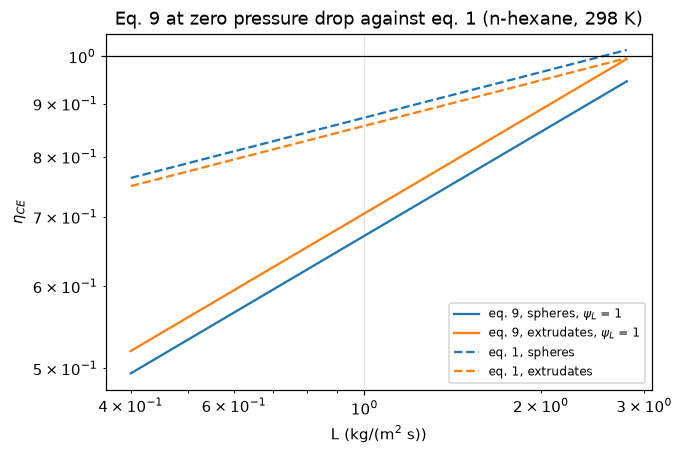

At equal $L$ and $\psi_L$ eq. 9 puts the extrudate bed at 1.0509 times the sphere bed: this is $(\varepsilon_{B,sph}/\varepsilon_{B,ext})^{1/3}$ and nothing else, because doubling $d_p$ changes eq. 9 by below 1e-14 (the bound is 1e-12) and the full groups equal the reduced form to below 1e-14. Eq. 1 puts the extrudates at 0.9820 of the spheres, through $d_p^{-0.0672}$ alone. So eq. 9 contains no particle-size effect: its prediction for the two beds runs opposite to the authors' reading that wetting rises as the particle diameter falls, while eq. 1 runs with it. At $\psi_L$ = 1 eq. 9 is 0.769 of eq. 1 for the spheres and 0.823 for the extrudates at $L$ = 1 kg/(m² s), and its slope in $L$ is 1/3 against 0.1461: eq. 9 reduces to El-Hisnawi's correlation in form (the $\psi_L$ term vanishes), not in value. Eq. 9 reaches 1 at $\psi_L$ = 1 for spheres at $L$ = 3.306 kg/(m² s) (closed form).

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.loglog(Mv["_Ls"], Mv["_e9s"], "C0-", label="eq. 9, spheres, $\\psi_L$ = 1")
ax.loglog(Mv["_Ls"], Mv["_e9x"], "C1-", label="eq. 9, extrudates, $\\psi_L$ = 1")
ax.loglog(Mv["_Ls"], Mv["_e1s"], "C0--", label="eq. 1, spheres")
ax.loglog(Mv["_Ls"], Mv["_e1x"], "C1--", label="eq. 1, extrudates")
ax.axhline(1.0, color="k", lw=0.8)
ax.set_xlabel("L (kg/(m$^2$ s))"); ax.set_ylabel("$\\eta_{CE}$"); ax.legend(fontsize=8)
ax.set_title("Eq. 9 at zero pressure drop against eq. 1 (n-hexane, 298 K)")
plt.show()
say("At equal $L$ and $\\psi_L$ eq. 9 puts the extrudate bed at <<a:.4f>> times the sphere bed: this is "
    "$(\\varepsilon_{B,sph}/\\varepsilon_{B,ext})^{1/3}$ and nothing else, because doubling $d_p$ changes eq. 9 by "
    "<<g>> (the bound is 1e-12) and the full groups equal the reduced form to <<r>>. Eq. 1 puts the "
    "extrudates at <<b:.4f>> of the spheres, through $d_p^{-0.0672}$ alone. So eq. 9 contains no particle-size effect: "
    "its prediction for the two beds runs opposite to the authors' reading that wetting rises as the particle "
    "diameter falls, while eq. 1 runs with it. At $\\psi_L$ = 1 eq. 9 is <<c:.3f>> of eq. 1 for the spheres and "
    "<<d:.3f>> for the extrudates at $L$ = 1 kg/(m² s), and its slope in $L$ is 1/3 against 0.1461: eq. 9 "
    "reduces to El-Hisnawi's correlation in form (the $\\psi_L$ term vanishes), not in value. Eq. 9 reaches 1 at "
    "$\\psi_L$ = 1 for spheres at $L$ = <<l:.3f>> kg/(m² s) (closed form).",
    a=Mv["r1_ext_over_sph_eq9"], g=below(Mv["r1_dp_doubled_gap"], 1e-14), r=below(Mv["r1_reduced_gap"], 1e-14), b=Mv["r1_ext_over_sph_eq1"],
    c=Mv["r1_eq9_over_eq1_sph_psi1"], d=Mv["r1_eq9_over_eq1_ext_psi1"], l=Mv["r1_lfull_sph_psi1"])

### R2. Route A: eq. 9 recomputed at the 37 paired points

Prediction from eq. 9 with the printed constants, $L$ from panel (a), the measured
$(\Delta P/Z)/(\rho_L g)$ from panel (b), $\varepsilon_B$ of Table 4 and n-hexane at
0.31 MPa. Markers: blue spheres, orange extrudates; the dashed lines are ±10 %.

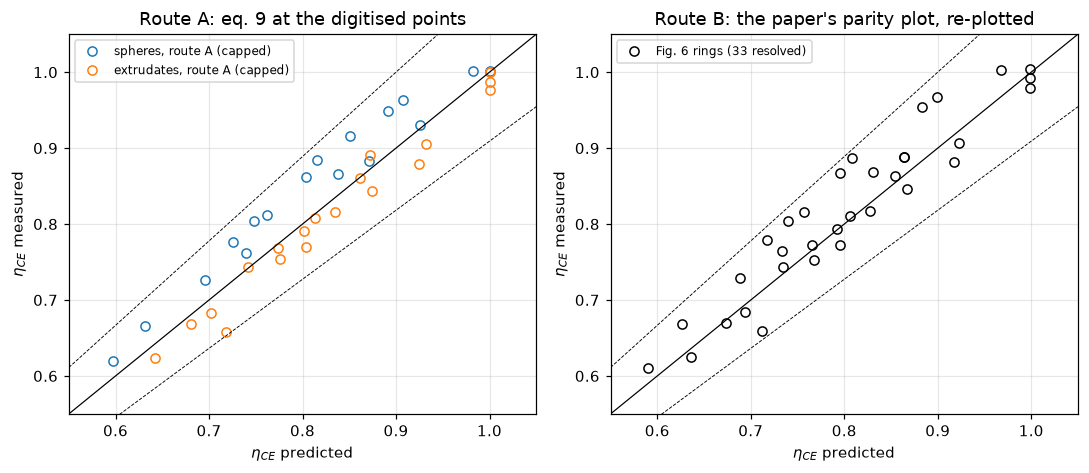

,capped,uncapped
(p - e)/e,"3.32 %, max 9.33 %, 37 of 37 inside","4.01 %, max 11.48 %, 36 of 37 inside"
(p - e)/p,"3.39 %, max 8.53 %, 37 of 37 inside","4.03 %, max 10.29 %, 36 of 37 inside"


With predictions capped at 1 and the deviation $(p-e)/e$, eq. 9 reproduces the 37 points with a mean relative error of 3.32 % (reading SD 0.038 % from 2000 Monte Carlo draws of every reading); the largest deviation is 9.33 %, and with two reading SDs added it is 9.64 %, so 37 of 37 points are inside ±10 % by more than two reading SDs. Uncapped, eq. 9 exceeds 1 at 5 points, the mean error is 4.01 % and 36 of 37 points are inside; the worst is the extrudate point of case 5b at $L$ = 2.32 kg/(m² s), +11.5 %. Liquid properties taken at each case's pressure instead of 0.31 MPa move the capped error to 3.31 %; the paper does not print the properties it used.

In [9]:
P0 = Mv["_P"]
fig, axs = plt.subplots(1, 2, figsize=(10, 4.4))
for bed, col in (("sphere", "C0"), ("extrudate", "C1")):
    s_ = (P0.bed == bed).to_numpy()
    axs[0].plot(Mv["_pc"][s_], P0.eta[s_], "o", mfc="none", color=col, label=f"{bed}s, route A (capped)")
xx = np.array([0.55, 1.05])
for ax_ in axs:
    ax_.plot(xx, xx, "k-", lw=0.8)
    ax_.plot(xx, xx / 1.1, "k--", lw=0.6)
    ax_.plot(xx, xx / 0.9, "k--", lw=0.6)
    ax_.set_xlim(0.55, 1.05); ax_.set_ylim(0.55, 1.05)
    ax_.set_xlabel("$\\eta_{CE}$ predicted"); ax_.set_ylabel("$\\eta_{CE}$ measured")
axs[0].legend(fontsize=8); axs[0].set_title("Route A: eq. 9 at the digitised points")
axs[1].plot(F6.eta_pred, F6.eta_exp, "ko", mfc="none", label=f"Fig. 6 rings ({len(F6)} resolved)")
axs[1].legend(fontsize=8); axs[1].set_title("Route B: the paper's parity plot, re-plotted")
plt.tight_layout(); plt.show()
tab = pd.DataFrame({cap: {conv: f"{Mv[f'r2_mre_{cap}_{conv}'] * 100:.2f} %, max {Mv[f'r2_maxdev_{cap}_{conv}'] * 100:.2f} %, "
                          f"{Mv[f'r2_inside_{cap}_{conv}']} of {Mv['n_points']} inside"
                          for conv in ("exp", "pred")} for cap in ("capped", "uncapped")})
tab.index = ["(p - e)/e", "(p - e)/p"]
display(tab)
say("With predictions capped at 1 and the deviation $(p-e)/e$, eq. 9 reproduces the <<n:d>> points with a mean "
    "relative error of <<m:pct2>> (reading SD <<s:pct3>> from <<nmc:d>> Monte Carlo draws of every reading); the "
    "largest deviation is <<x:pct2>>, and with two reading SDs added it is <<x2:pct2>>, so <<ci:d>> of <<n:d>> points are "
    "inside ±10 % by more than two reading SDs. Uncapped, eq. 9 exceeds 1 at <<na:d>> points, the mean error is "
    "<<mu:pct2>> and <<iu:d>> of <<n:d>> points are inside; the worst is the <<wb>> point of case <<wc>> at "
    "$L$ = <<wl:.2f>> kg/(m² s), <<wd:+pct1>>. Liquid properties taken at each case's pressure instead of 0.31 MPa "
    "move the capped error to <<mp:pct2>>; the paper does not print the properties it used.",
    n=Mv["n_points"], m=Mv["r2_mre_capped_exp"], s=Mv["r2_mc_sd"], nmc=N_MC, x=Mv["r2_maxdev_capped_exp"],
    x2=Mv["r2_maxdev_plus_2sd"], ci=Mv["r2_n_certain_inside"], na=Mv["r2_n_pred_above_1"], mu=Mv["r2_mre_uncapped_exp"],
    iu=Mv["r2_inside_uncapped_exp"], wl=Mv["r2_uncapped_worst_L"], wd=Mv["r2_uncapped_worst_dev"],
    mp=Mv["r2_mre_case_props"], wb=P0.bed.iloc[int(np.argmax(np.abs(deviations(Mv["_pu"], P0.eta))))],
    wc=P0.case.iloc[int(np.argmax(np.abs(deviations(Mv["_pu"], P0.eta))))])

### R3. Route B: the paper's own predictions

Fig. 6 re-plotted above (right). Each ring is assigned to a measured point by its
experimental value (a least-squares assignment); a ring is ambiguous when its second
nearest point is within two reading SDs of the nearest. Rings below 0.985 give the
ratio of the authors' plotted prediction to eq. 9 at that point. Fig. 7's two lines
are compared with eq. 9 at the case-2 and case-5 pressure drops of Fig. 5b.

In [10]:
say("From the <<nr:d>> resolved rings of Fig. 6, the mean relative error is <<m:pct2>> in $(p-e)/e$ (reading SD "
    "<<s:pct3>>; <<mp:pct2>> in $(p-e)/p$), the largest deviation <<x:pct2>>, and <<ins:d>> of <<nr:d>> rings lie inside "
    "±10 %. If the corner stack hides rings up to the <<n:d>> points, each at zero deviation, the error would be "
    "<<m37:pct2>>. No ring lies above a predicted value of 1 by more than two reading SDs (<<na:d>> rings), while uncapped "
    "eq. 9 exceeds 1 at <<n9:d>> points: the plotted predictions are capped at 1, or were clipped by the frame. "
    "Matched rings sit at <<rs:.4f>> ± <<rss:.4f>> (<<ns:d>> rings, spheres) and <<rx:.4f>> ± <<rxs:.4f>> (<<nx:d>> rings, "
    "extrudates) of eq. 9 recomputed here (<<amb:d>> of <<nr:d>> assignments ambiguous): the prefactor the plotted "
    "predictions imply is <<pf:.4f>> times 1.104 with these liquid properties, a property choice or a rounding the "
    "paper does not state. Fig. 7's solid line (0.31 MPa) is <<f7s:.4f>> of eq. 9 at the case-2 pressure drops "
    "(spread <<f7ss:.4f>> along the line) with log-log slope <<sl:.3f>> against <<sle:.3f>> for eq. 9 there; the "
    "dashed line (3.55 MPa) is <<f7d:.4f>> of eq. 9 (spread <<f7ds:.4f>>, read from six dashes) with slope <<sd_:.3f>> "
    "against <<sde:.3f>>.",
    nr=Mv["r3_n_rings"], m=Mv["r3_mre_B"], s=Mv["r3_mc_sd"], mp=Mv["r3_mre_B_pred"], x=Mv["r3_maxdev_B"],
    ins=Mv["r3_inside_B"], n=Mv["n_points"], m37=Mv["r3_mre_B_37"], na=Mv["r3_n_pred_above_1"], n9=Mv["r2_n_pred_above_1"],
    rs=Mv["r3_ratio_sphere"], rss=Mv["r3_ratio_sphere_se"], ns=Mv["r3_ratio_sphere_n"], rx=Mv["r3_ratio_extrudate"],
    rxs=Mv["r3_ratio_extrudate_se"], nx=Mv["r3_ratio_extrudate_n"], amb=Mv["r3_n_ambiguous"], pf=Mv["r3_ratio_pooled"],
    f7s=Mv["r3_f7_solid_over_eq9"], f7ss=Mv["r3_f7_solid_over_eq9_spread"], sl=Mv["r3_f7_solid_slope"],
    sle=Mv["r3_f7_solid_eq9_slope"], f7d=Mv["r3_f7_dashed_over_eq9"], f7ds=Mv["r3_f7_dashed_over_eq9_spread"],
    sd_=Mv["r3_f7_dashed_slope"], sde=Mv["r3_f7_dashed_eq9_slope"])

From the 33 resolved rings of Fig. 6, the mean relative error is 3.67 % in $(p-e)/e$ (reading SD 0.074 %; 3.83 % in $(p-e)/p$), the largest deviation 8.83 %, and 33 of 33 rings lie inside ±10 %. If the corner stack hides rings up to the 37 points, each at zero deviation, the error would be 3.27 %. No ring lies above a predicted value of 1 by more than two reading SDs (0 rings), while uncapped eq. 9 exceeds 1 at 5 points: the plotted predictions are capped at 1, or were clipped by the frame. Matched rings sit at 0.9904 ± 0.0069 (14 rings, spheres) and 0.9902 ± 0.0003 (16 rings, extrudates) of eq. 9 recomputed here (20 of 33 assignments ambiguous): the prefactor the plotted predictions imply is 0.9903 times 1.104 with these liquid properties, a property choice or a rounding the paper does not state. Fig. 7's solid line (0.31 MPa) is 0.9971 of eq. 9 at the case-2 pressure drops (spread 0.0042 along the line) with log-log slope 0.340 against 0.335 for eq. 9 there; the dashed line (3.55 MPa) is 0.9868 of eq. 9 (spread 0.0105, read from six dashes) with slope 0.339 against 0.356.

### R4. What the residuals hold

Residual $(p-e)/e$ of route A against $\psi_L$, by bed. Refits use the points
below the $\eta_{CE}$ = 1 frame: (a) eq. 6 with the eq. 9 groups, ordinary least squares in logs; (b)
a bed-offset form $\ln\eta = a_{bed} + n\ln L + m\ln\psi_L$, whose $n$ and $m$ come
from variation within each bed. Intervals: a bootstrap that resamples the (bed, case)
clusters, and leave-one-case-out refits.

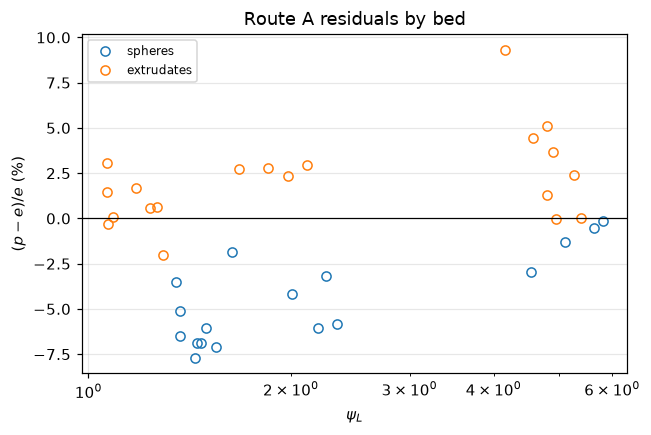

The residuals split by bed: spheres -4.46 % ± 0.60 % (17 points), extrudates +2.11 % ± 0.55 % (20), a difference of 6.57 % at 8.1 two-sample standard errors. The bed-offset refit puts the extrudates at 0.9741 times the spheres at equal $L$ and $\psi_L$, where eq. 9 says 1.0509 and eq. 1 0.9820. Eq. 6 refitted: $c$ = 0.854, $n$ = 0.331 ± 0.023, $m$ = 0.085 ± 0.013 (OLS SEs): 1/3 lies 0.08 SEs and 1/9 1.95 SEs from these, because in eq. 6 the bed term moves both exponents. Within the beds (form b) $n$ = 0.3608 ± 0.0065 and $m$ = 0.0790 ± 0.0038: 1/9 lies 8.5 SEs above $m$ and 1/3 lies 4.2 SEs from $n$. The cluster bootstrap gives $m$ in [0.0704, 0.0889] and $n$ in [0.3446, 0.3739] (95 %, 2000 draws, 0.6 % of them singular), leave-one-case-out $m$ from 0.0740 to 0.0816 and $n$ from 0.3555 to 0.3636. With the four frame points included, $m$ = 0.0726.

The paper attributes the gain from case 2 (0.31 MPa, low gas rate) to case 5 (3.55 MPa, high gas rate) as "about 20% improvement in the extrudate bed (Fig. 5) and about 10% improvement in the bed of spheres (Fig. 4)" (p. 2386). At matched $L$ (case 2 interpolated log-log, no extrapolation) the data give 7.2 % to 12.3 % for spheres (4 points) and 14.0 % to 14.4 % for extrudates (3); eq. 9 at the same pressure drops gives 14.4 % to 16.5 % and 17.6 % to 19.2 %. The 10 % for spheres matches the data; the 20 % for extrudates is closer to eq. 9 than to the Fig. 5 data.

In [11]:
fig, ax = plt.subplots(figsize=(6.4, 4.0))
for bed, col in (("sphere", "C0"), ("extrudate", "C1")):
    s_ = (P0.bed == bed).to_numpy()
    ax.semilogx(psi_l(P0.dpz[s_]), 100 * Mv["_dev"][s_], "o", mfc="none", color=col, label=f"{bed}s")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("$\\psi_L$"); ax.set_ylabel("$(p - e)/e$ (%)"); ax.legend(fontsize=8)
ax.set_title("Route A residuals by bed")
plt.show()
say("The residuals split by bed: spheres <<bs:+pct2>> ± <<bss:pct2>> (<<n1:d>> points), extrudates <<bx:+pct2>> ± "
    "<<bxs:pct2>> (<<n2:d>>), a difference of <<d:pct2>> at <<z:.1f>> two-sample standard errors. The bed-offset refit "
    "puts the extrudates at <<rr:.4f>> times the spheres at equal $L$ and $\\psi_L$, where eq. 9 says <<r9:.4f>> and eq. 1 "
    "<<r1:.4f>>. Eq. 6 refitted: $c$ = <<c6:.3f>>, $n$ = <<n6:.3f>> ± <<n6s:.3f>>, $m$ = <<m6:.3f>> ± <<m6s:.3f>> (OLS "
    "SEs): 1/3 lies <<d6n:.2f>> SEs and 1/9 <<d6m:.2f>> SEs from these, because in eq. 6 the bed term moves both exponents. Within the "
    "beds (form b) $n$ = <<nb:.4f>> ± <<nbs:.4f>> and $m$ = <<mb:.4f>> ± <<mbs:.4f>>: 1/9 lies <<dm:.1f>> SEs above $m$ and "
    "1/3 lies <<dn:.1f>> SEs from $n$. The cluster bootstrap gives $m$ in [<<ml:.4f>>, <<mh:.4f>>] and $n$ in "
    "[<<nl:.4f>>, <<nh:.4f>>] (95 %, <<nb_:d>> draws, <<sg:pct1>> of them singular), leave-one-case-out $m$ from "
    "<<mlo:.4f>> to <<mhi:.4f>> and $n$ from <<nlo:.4f>> to <<nhi:.4f>>. With the four frame points included, $m$ = "
    "<<mf:.4f>>.",
    bs=Mv["r4_bias_sphere"], bss=Mv["r4_bias_sphere_se"], n1=int((P0.bed == "sphere").sum()), bx=Mv["r4_bias_extrudate"],
    bxs=Mv["r4_bias_extrudate_se"], n2=int((P0.bed == "extrudate").sum()), d=Mv["r4_bias_diff"], z=Mv["r4_bias_z"],
    rr=Mv["r4_bed_ratio_ext_sph"], r9=Mv["r1_ext_over_sph_eq9"], r1=Mv["r1_ext_over_sph_eq1"], c6=Mv["r4_eq6_c"],
    n6=Mv["r4_eq6_n"], n6s=Mv["r4_eq6_n_se"], m6=Mv["r4_eq6_m"], m6s=Mv["r4_eq6_m_se"], nb=Mv["r4_n"], nbs=Mv["r4_n_se"],
    mb=Mv["r4_m"], mbs=Mv["r4_m_se"], dm=Mv["r4_m_dist_19_se"], dn=abs(Mv["r4_n_dist_13_se"]), ml=Mv["r4_m_lo"],
    mh=Mv["r4_m_hi"], nl=Mv["r4_n_lo"], nh=Mv["r4_n_hi"], nb_=N_BOOT, sg=Mv["r4_boot_singular_frac"],
    mlo=Mv["r4_m_loco_min"], mhi=Mv["r4_m_loco_max"], nlo=Mv["r4_n_loco_min"], nhi=Mv["r4_n_loco_max"],
    mf=Mv["r4_m_with_frame"], d6n=Mv["r4_eq6_n_dist_13_se"], d6m=Mv["r4_eq6_m_dist_19_se"])
say("The paper attributes the gain from case 2 (0.31 MPa, low gas rate) to case 5 (3.55 MPa, high gas rate) as "
    "\"about 20% improvement in the extrudate bed (Fig. 5) and about 10% improvement in the bed of spheres (Fig. 4)\" "
    "(p. 2386). At matched $L$ (case 2 interpolated log-log, no extrapolation) the data give <<sa:pct1>> to <<sb:pct1>> "
    "for spheres (<<ns:d>> points) and <<xa:pct1>> to <<xb:pct1>> for extrudates (<<nx:d>>); eq. 9 at the same pressure "
    "drops gives <<ea:pct1>> to <<eb:pct1>> and <<fa:pct1>> to <<fb:pct1>>. The 10 % for spheres matches the data; the "
    "20 % for extrudates is closer to eq. 9 than to the Fig. 5 data.",
    sa=Mv["r4_gain_sphere_data_min"] - 1, sb=Mv["r4_gain_sphere_data_max"] - 1, ns=Mv["r4_gain_sphere_n"],
    xa=Mv["r4_gain_extrudate_data_min"] - 1, xb=Mv["r4_gain_extrudate_data_max"] - 1, nx=Mv["r4_gain_extrudate_n"],
    ea=Mv["r4_gain_sphere_eq9_min"] - 1, eb=Mv["r4_gain_sphere_eq9_max"] - 1,
    fa=Mv["r4_gain_extrudate_eq9_min"] - 1, fb=Mv["r4_gain_extrudate_eq9_max"] - 1)

### R5. El-Hisnawi's eq. 1 at 0.31 MPa

The paper: "which predicts higher contacting values than both sets of data but within
the error margin of the correlation (± 10%)" (p. 2387). Eq. 1 at the 0.31 MPa points
(cases 2 and 3 of both beds), each decided against its reading SD.

In [12]:
r5t = Mv["_r5"][["bed", "case", "L", "eta", "eta1", "excess"]].sort_values(["bed", "case", "L"])
display(r5t.assign(L=r5t.L.round(3), eta=r5t.eta.round(4), eta1=r5t.eta1.round(4), excess=(100 * r5t.excess).round(1)))
say("Eq. 1 lies above the data at <<a:d>> of <<n:d>> points (<<ad:d>> of them by more than two reading SDs; case 2 "
    "alone <<a2:d>> of <<n2:d>>), and within ±10 % at <<w:d>> of <<n:d>> (case 2 alone <<w2:d>> of <<n2:d>>); <<o:d>> "
    "points lie outside ±10 % by more than two reading SDs. The largest excess is <<x:+pct1>> at $L$ = <<xl:.2f>> "
    "kg/(m² s). The first half of the sentence holds at <<a:d>> of <<n:d>> points; the second half holds at <<w:d>> of "
    "<<n:d>>, so as a statement about every point it does not.",
    a=Mv["r5_above"], n=Mv["r5_n"], ad=Mv["r5_above_decided"], a2=Mv["r5_above_case2"], n2=Mv["r5_n_case2"],
    w=Mv["r5_within10"], w2=Mv["r5_within10_case2"], o=Mv["r5_outside10_decided"], x=Mv["r5_max_excess"],
    xl=Mv["r5_max_excess_L"])

,bed,case,L,eta,eta1,excess
17,extrudate,2,0.739,0.6230,0.8199,31.6
18,extrudate,2,1.134,0.7435,0.8729,17.4
19,extrudate,2,1.439,0.7905,0.9038,14.3
20,extrudate,2,1.774,0.8611,0.9318,8.2
21,extrudate,3,0.830,0.6832,0.8339,22.1
22,extrudate,3,1.083,0.7546,0.8670,14.9
23,extrudate,3,1.321,0.8157,0.8926,9.4
24,extrudate,3,1.795,0.9050,0.9334,3.1
0,sphere,2,0.638,0.6191,0.8171,32.0
1,sphere,2,1.139,0.7765,0.8894,14.5


Eq. 1 lies above the data at 16 of 17 points (16 of them by more than two reading SDs; case 2 alone 9 of 9), and within ±10 % at 9 of 17 (case 2 alone 4 of 9); 8 points lie outside ±10 % by more than two reading SDs. The largest excess is +32.0 % at $L$ = 0.64 kg/(m² s). The first half of the sentence holds at 16 of 17 points; the second half holds at 9 of 17, so as a statement about every point it does not.

### R6. The measurement chain: moment coefficients by pymrm, and the tables' factor 2

The pellet BVP of the implementation section, solved on 40, 80, 160 and 320 cells for
a sphere, an infinite cylinder and a slab, without film and with a film at $Bi$ = 5.
Then the tracer relations at a test condition (condition T2 of the check values: the
sphere bed of Table 4, $Q_L$ = 50 ml/min, assumed $D_{e,LF}$ = 1.0e-9 and
$D_{e,TF}$ = 0.64e-9 m²/s, $\varepsilon_L$ = 0.15, plug flow, no film).

In [13]:
r6t = pd.DataFrame([{"case": nm, "Richardson value": Mv[f"r6_coef_{nm}"],
                     "exact": MOMENT_EXACT[nu] + (FILM_EXACT[nu] / bi if bi else 0.0),
                     "gap": below(Mv[f"r6_gap_{nm}"], 1e-10), "orders": f"{Mv[f'r6_order_min_{nm}']:.5f} to {Mv[f'r6_order_max_{nm}']:.5f}",
                     "finest step / round-off": above(Mv[f"r6_roundoff_ratio_{nm}"], 1e6)}
                    for nm, nu, bi in (("sphere", 2, None), ("cylinder", 1, None), ("slab", 0, None),
                                       ("sphere_bi5", 2, 5.0), ("cylinder_bi5", 1, 5.0), ("slab_bi5", 0, 5.0))])
display(r6t)
_gmax = max(Mv[f"r6_gap_{nm}"] for nm in r6t["case"])
_omin = min(Mv[f"r6_order_min_{nm}"] for nm in r6t["case"])
_omax = max(Mv[f"r6_order_max_{nm}"] for nm in r6t["case"])
say("The observed orders lie between <<a:.4f>> and <<b:.4f>> (theory 2), every Richardson value is within 1e-8 of "
    "its rational (here <<g>>), and the finest-grid step is <<r>> times the gap to a dense "
    "LAPACK solve of the same system. These are the coefficients behind Tables 1 and 2: Table 2's "
    "$\\delta_i = ((1-\\varepsilon_B)\\varepsilon_p/\\varepsilon_B)\\,r_p^2\\varepsilon_p/(15 D_e)$ is $1/15$ times "
    "the pellet term, Table 1's $(r_p^2\\varepsilon_p/8)$ is the cylinder's $1/8$. The variance of a pulse through "
    "plug flow with pellets is $2 t_f\\delta_0'\\tau_1$ (second cumulant), but Table 2 and Table 1's liquid-filled lines "
    "write the reduced variance without the 2: at T2 Table 2's $\\sigma_D^2$ is <<t:.4f>> of the standard one, and "
    "$D_e$ recovered from a measured variance with Table 2 is <<de:.4f>> of the true value. In eq. 8 the factor cancels "
    "when the liquid-filled and two-phase variances use the same form; combining Table 1's two-phase $\\sigma^2$ "
    "line (which carries the full form) with the liquid-filled slope would give <<mx:.5f>> times the true "
    "$\\eta_{CE}$. Which form the authors used is not stated; this page tests no tracer data.",
    a=_omin, b=_omax, g=below(_gmax, 1e-10), r=above(min(Mv[f"r6_roundoff_ratio_{nm}"] for nm in r6t["case"]), 1e6),
    t=Mv["r6_table2_over_standard"], de=Mv["r6_de_recovered_over_true"], mx=Mv["r6_eta_mixed_over_true"])

,case,Richardson value,exact,gap,orders,finest step / round-off
0,sphere,0.066667,0.066667,below 1e-10,1.99986 to 1.99997,above 1e+06
1,cylinder,0.125000,0.125000,below 1e-10,2.00000 to 2.00000,above 1e+06
2,slab,0.333333,0.333333,below 1e-10,2.00000 to 2.00000,above 1e+06
3,sphere_bi5,0.133333,0.133333,below 1e-10,1.99986 to 1.99997,above 1e+06
4,cylinder_bi5,0.225000,0.225000,below 1e-10,2.00000 to 2.00000,above 1e+06
5,slab_bi5,0.533333,0.533333,below 1e-10,2.00000 to 2.00000,above 1e+06


The observed orders lie between 1.9999 and 2.0000 (theory 2), every Richardson value is within 1e-8 of its rational (here below 1e-10), and the finest-grid step is above 1e+06 times the gap to a dense LAPACK solve of the same system. These are the coefficients behind Tables 1 and 2: Table 2's $\delta_i = ((1-\varepsilon_B)\varepsilon_p/\varepsilon_B)\,r_p^2\varepsilon_p/(15 D_e)$ is $1/15$ times the pellet term, Table 1's $(r_p^2\varepsilon_p/8)$ is the cylinder's $1/8$. The variance of a pulse through plug flow with pellets is $2 t_f\delta_0'\tau_1$ (second cumulant), but Table 2 and Table 1's liquid-filled lines write the reduced variance without the 2: at T2 Table 2's $\sigma_D^2$ is 0.5000 of the standard one, and $D_e$ recovered from a measured variance with Table 2 is 0.5000 of the true value. In eq. 8 the factor cancels when the liquid-filled and two-phase variances use the same form; combining Table 1's two-phase $\sigma^2$ line (which carries the full form) with the liquid-filled slope would give 1.41421 times the true $\eta_{CE}$. Which form the authors used is not stated; this page tests no tracer data.

## Validation

**V1, digitising.** Duplicate readings of the same quantity from different panels.
**V2, printed inputs.** Tables 3 and 4 against what they imply, in half-units of the
last printed digit. **V3** is the check-value table above. **V4** is the order and
Richardson study of R6. **V5** fixes the Monte Carlo and bootstrap draw counts.

In [14]:
say("V1. $L$ of each run read from panel (a) and from panel (b) agrees to <<a:pct2>> at worst (mean <<b:+pct2>>, <<n:d>> "
    "pairs; the stop rule was 1.5 %). Fig. 7's seven markers agree with the Fig. 5a points of the same case to "
    "<<c:pct2>> in $L$ and <<d:pct2>> in $\\eta_{CE}$; Fig. 6's unambiguously matched rings agree with the Fig. 4a and 5a "
    "values to <<e:pct2>> in $\\eta_{CE}$.",
    a=Mv["v1_L_ab_max"], b=Mv["v1_L_ab_mean"], c=Mv["v1_f7_vs_f5a_L_max"], d=Mv["v1_f7_vs_f5a_eta_max"],
    e=Mv["v1_f6_vs_points_eta_max"], n=Mv["n_points"])
v2t = pd.DataFrame([("30 psig in MPa absolute, against 0.31", f"{Mv['v2_hu_p30']:.3f}"),
                    ("700 psig in MPa absolute, against 4.93", f"{Mv['v2_hu_p700']:.3f}"),
                    ("700 psig in MPa absolute, against Table 3's 5.0", f"{Mv['v2_hu_p700_vs_5p0']:.3f}"),
                    ("6 V_p/S_ex of 0.157 x 0.43 cm, against (d_p)_eq 0.199", f"{Mv['v2_hu_deq']:.3f}"),
                    ("d_r/d_p extrudates, against 11", f"{Mv['v2_hu_drdp_ext']:.3f}"),
                    ("d_r/d_p spheres, against 14.6", f"{Mv['v2_hu_drdp_sph']:.3f}"),
                    ("ideal N2 G at 4.93 MPa and 7.20 cm/s, against G_max 4.03", f"{Mv['v2_hu_gmax']:.3f}")],
                   columns=["quantity", "half-units"])
display(v2t)
say("V2. <<n:d>> of the <<nt:d>> rows that recompute a printed entry from other printed numbers (the two pressures, "
    "$(d_p)_{eq}$ and both $d_r/d_p$) lie within one half-unit of it; Table 3's upper pressure 5.0 MPa is <<p:.2f>> "
    "half-units from 700 psig. Ideal nitrogen at 4.93 MPa and 7.20 cm/s gives $G$ = <<g:.4f>> kg/(m² s), <<gh:.2f>> "
    "half-units below the printed 4.03; the gas is taken as ideal here. The printed $G_{min}$ = 6.64e-3 does not follow from 0.31 MPa and 1 cm/s: ideal nitrogen gives "
    "<<gr:.3f>> times that. Table 3's $L$ and $Q_L$ ranges imply a liquid density of <<rl:.1f>> to <<rh:.1f>> kg/m³ "
    "(the extremes of the two reactor diameters), bracketing the NIST value <<rn:.1f>> kg/m³.",
    n=Mv["v2_n_within"], nt=5,
    p=Mv["v2_hu_p700_vs_5p0"], g=Mv["v2_gmax"], gh=Mv["v2_hu_gmax"], gr=Mv["v2_gmin_ratio"], rl=Mv["v2_rho_lo"],
    rh=Mv["v2_rho_hi"], rn=props_at(C0, "0.31")[0])

V1. $L$ of each run read from panel (a) and from panel (b) agrees to 0.96 % at worst (mean -0.11 %, 37 pairs; the stop rule was 1.5 %). Fig. 7's seven markers agree with the Fig. 5a points of the same case to 0.70 % in $L$ and 0.19 % in $\eta_{CE}$; Fig. 6's unambiguously matched rings agree with the Fig. 4a and 5a values to 1.30 % in $\eta_{CE}$.

,quantity,half-units
0,"30 psig in MPa absolute, against 0.31",0.366
1,"700 psig in MPa absolute, against 4.93",0.469
2,"700 psig in MPa absolute, against Table 3's 5.0",1.447
3,"6 V_p/S_ex of 0.157 x 0.43 cm, against (d_p)_e...",0.289
4,"d_r/d_p extrudates, against 11",0.006
5,"d_r/d_p spheres, against 14.6",0.105
6,"ideal N2 G at 4.93 MPa and 7.20 cm/s, against ...",3.353


V2. 5 of the 5 rows that recompute a printed entry from other printed numbers (the two pressures, $(d_p)_{eq}$ and both $d_r/d_p$) lie within one half-unit of it; Table 3's upper pressure 5.0 MPa is 1.45 half-units from 700 psig. Ideal nitrogen at 4.93 MPa and 7.20 cm/s gives $G$ = 4.0132 kg/(m² s), 3.35 half-units below the printed 4.03; the gas is taken as ideal here. The printed $G_{min}$ = 6.64e-3 does not follow from 0.31 MPa and 1 cm/s: ideal nitrogen gives 5.278 times that. Table 3's $L$ and $Q_L$ ranges imply a liquid density of 632.8 to 674.3 kg/m³ (the extremes of the two reactor diameters), bracketing the NIST value 655.2 kg/m³.

**V5.** The Monte Carlo SDs and the bootstrap interval are rerun with twelve other
seeds; each claim's tolerance is three times the largest relative move a seed causes.

In [15]:
MC_KEYS = ("r2_mc_sd", "r3_mc_sd", "r4_m_lo", "r4_m_hi", "r4_n_lo", "r4_n_hi")


def seeded(seed):
    """The sampled quantities with another generator seed."""
    rng = np.random.default_rng(seed)
    P = points(C0)
    pc = pred9(P, C0, K, cap=True)
    out = r2(C0, K, P, rng)
    out |= r3(C0, K, P, pc, rng)
    out |= r4(C0, K, P, pc, rng)
    return {k: out[k] for k in MC_KEYS}


_seeds = [seeded(s) for s in range(1, 13)]
MC_MOVE = {k: max(abs(d[k] / Mv[k] - 1) for d in _seeds) for k in MC_KEYS}
MC_RTOL = {k: 3 * v for k, v in MC_MOVE.items()}
display(pd.DataFrame({"value": {k: Mv[k] for k in MC_KEYS}, "largest seed move": MC_MOVE, "tolerance (rtol)": MC_RTOL}))

,value,largest seed move,tolerance (rtol)
r2_mc_sd,0.000378,0.032808,0.098424
r3_mc_sd,0.000736,0.033598,0.100795
r4_m_lo,0.070448,0.009141,0.027423
r4_m_hi,0.088860,0.007517,0.022552
r4_n_lo,0.344624,0.003107,0.009322
r4_n_hi,0.373905,0.002768,0.008303


### The gates

Pass criteria written before the run (build plan): G1 "reproduced" if
$|MRE_A - 3.7\,\%| \le 0.05\,\% + 2s$, else "inside the band" if 3.7 % lies in the band
of unprinted choices (capped or not, either convention, prefactor 1 or the route-B
value), else "not reproduced"; G2 the same for Fig. 6 with $s$ from the ring reading
error and half the shift a full count of rings could cause; G3 "all inside" only if the
largest deviation plus 2 SD is at most 10 %; G4 a split only at 3 two-sample SEs or
more; G5 an exponent "excluded" only if outside the bootstrap interval and outside every
leave-one-case-out estimate; G6 counts with totals; G7 orders 1.95 to 2.05 and
Richardson values within 1e-8.

In [16]:
gates = pd.DataFrame([
    ("G1 route A", f"MRE {Mv['r2_mre_capped_exp'] * 100:.2f} %, s {Mv['r2_mc_sd'] * 100:.3f} %, band "
                   f"[{Mv['g1_band_lo'] * 100:.2f}, {Mv['g1_band_hi'] * 100:.2f}] %", Mv["g1_verdict"]),
    ("G2 route B", f"MRE {Mv['r3_mre_B'] * 100:.2f} %, s {Mv['g2_s'] * 100:.3f} %", Mv["g2_verdict"]),
    ("G3 ±10 %", f"largest {Mv['r2_maxdev_capped_exp'] * 100:.2f} %, + 2 SD {Mv['r2_maxdev_plus_2sd'] * 100:.2f} %; "
                 f"uncapped {Mv['r2_inside_uncapped_exp']} of {Mv['n_points']}", Mv["g3_verdict"]),
    ("G4 bed split", f"{Mv['r4_bias_diff'] * 100:.2f} % at {Mv['r4_bias_z']:.1f} SE", Mv["g4_verdict"]),
    ("G5 m = 1/9", f"bootstrap [{Mv['r4_m_lo']:.4f}, {Mv['r4_m_hi']:.4f}], LOCO [{Mv['r4_m_loco_min']:.4f}, "
                   f"{Mv['r4_m_loco_max']:.4f}]", "excluded" if Mv["r4_m_excludes_19"] else "not excluded"),
    ("G5 n = 1/3", f"bootstrap [{Mv['r4_n_lo']:.4f}, {Mv['r4_n_hi']:.4f}], LOCO [{Mv['r4_n_loco_min']:.4f}, "
                   f"{Mv['r4_n_loco_max']:.4f}]", "excluded" if Mv["r4_n_excludes_13"] else "not excluded"),
    ("G6 El-Hisnawi", f"above {Mv['r5_above']} of {Mv['r5_n']}, within 10 % {Mv['r5_within10']} of {Mv['r5_n']}", "counts"),
    ("G7 BVP", f"orders {_omin:.4f} to {_omax:.4f}, gaps {below(_gmax, 1e-10)}",
     "pass" if 1.95 <= _omin and _omax <= 2.05 and _gmax <= 1e-8 else "fail"),
], columns=["gate", "measured", "verdict"])
display(gates)

,gate,measured,verdict
0,G1 route A,"MRE 3.32 %, s 0.038 %, band [3.32, 4.13] %",inside the band
1,G2 route B,"MRE 3.67 %, s 0.212 %",reproduced
2,G3 ±10 %,"largest 9.33 %, + 2 SD 9.64 %; uncapped 36 of 37",all inside
3,G4 bed split,6.57 % at 8.1 SE,split
4,G5 m = 1/9,"bootstrap [0.0704, 0.0889], LOCO [0.0740, 0.0816]",excluded
5,G5 n = 1/3,"bootstrap [0.3446, 0.3739], LOCO [0.3555, 0.3636]",excluded
6,G6 El-Hisnawi,"above 16 of 17, within 10 % 9 of 17",counts
7,G7 BVP,"orders 1.9999 to 2.0000, gaps below 1e-10",pass


### The finding

In [17]:
say("**G1.** Route A gives <<ma:pct2>> against \"The mean relative error is 3.7%.\" (p. 2386): <<dA:+pct2>> from it, "
    "verdict \"<<g1>>\" (the band of unprinted choices runs from <<bl:pct2>> to <<bh:pct2>>). **G2.** The paper's own "
    "parity plot gives <<mb:pct2>>: verdict \"<<g2>>\". So the printed 3.7 % is what Fig. 6 shows, and eq. 9 as printed, "
    "at n-hexane properties, lands near it rather than on it. **G3.** \"The data are bounded by ± 10%.\": "
    "\"<<g3>>\" for capped predictions (<<ci:d>> of <<n:d>> points by two reading SDs); uncapped, <<iu:d>> of <<n:d>>. "
    "**G4.** The residuals split by bed (\"<<g4>>\", <<z:.1f>> SEs): spheres below eq. 9, extrudates above it. "
    "**G5.** Within the beds the exponent on $\\psi_L$ is <<m:.4f>>: 1/9 is <<g5m>> by the data (outside the bootstrap "
    "interval and every leave-one-case-out value), and the within-bed $L$ exponent <<n_:.4f>> has 1/3 <<g5n>>; eq. 6 with "
    "free exponents does not show this because its bed term absorbs it. The data put the extrudates below the spheres "
    "at equal $L$ and $\\psi_L$, where eq. 9 puts them above through $\\varepsilon_B^{-1/3}$ alone: the exponents of eq. "
    "9 average over two beds rather than describe either. **G6.** Eq. 1 lies above the data at <<a:d>> of <<n5:d>> "
    "points at 0.31 MPa but within ±10 % at only <<w:d>> of <<n5:d>>, so \"within the error margin of the correlation "
    "(± 10%)\" (p. 2387) does not hold point by point. **G7.** The pellet moment problem converges at second order "
    "onto 1/15, 1/8 and 1/3 (with film terms); Tables 1 and 2 write the reduced variance without the factor 2 of the "
    "second cumulant, which cancels in eq. 8 only when both variances use that form. Nothing here tests the tracer "
    "data, the holdup or Holub's model.",
    ma=Mv["r2_mre_capped_exp"], dA=Mv["g1_distance"], g1=Mv["g1_verdict"], bl=Mv["g1_band_lo"], bh=Mv["g1_band_hi"],
    mb=Mv["r3_mre_B"], g2=Mv["g2_verdict"], g3=Mv["g3_verdict"], ci=Mv["r2_n_certain_inside"], n=Mv["n_points"],
    iu=Mv["r2_inside_uncapped_exp"], g4=Mv["g4_verdict"], z=Mv["r4_bias_z"], m=Mv["r4_m"],
    g5m="excluded" if Mv["r4_m_excludes_19"] else "not excluded", n_=Mv["r4_n"],
    g5n="excluded" if Mv["r4_n_excludes_13"] else "not excluded", a=Mv["r5_above"], n5=Mv["r5_n"], w=Mv["r5_within10"])

**G1.** Route A gives 3.32 % against "The mean relative error is 3.7%." (p. 2386): -0.38 % from it, verdict "inside the band" (the band of unprinted choices runs from 3.32 % to 4.13 %). **G2.** The paper's own parity plot gives 3.67 %: verdict "reproduced". So the printed 3.7 % is what Fig. 6 shows, and eq. 9 as printed, at n-hexane properties, lands near it rather than on it. **G3.** "The data are bounded by ± 10%.": "all inside" for capped predictions (37 of 37 points by two reading SDs); uncapped, 36 of 37. **G4.** The residuals split by bed ("split", 8.1 SEs): spheres below eq. 9, extrudates above it. **G5.** Within the beds the exponent on $\psi_L$ is 0.0790: 1/9 is excluded by the data (outside the bootstrap interval and every leave-one-case-out value), and the within-bed $L$ exponent 0.3608 has 1/3 excluded; eq. 6 with free exponents does not show this because its bed term absorbs it. The data put the extrudates below the spheres at equal $L$ and $\psi_L$, where eq. 9 puts them above through $\varepsilon_B^{-1/3}$ alone: the exponents of eq. 9 average over two beds rather than describe either. **G6.** Eq. 1 lies above the data at 16 of 17 points at 0.31 MPa but within ±10 % at only 9 of 17, so "within the error margin of the correlation (± 10%)" (p. 2387) does not hold point by point. **G7.** The pellet moment problem converges at second order onto 1/15, 1/8 and 1/3 (with film terms); Tables 1 and 2 write the reduced variance without the factor 2 of the second cumulant, which cancels in eq. 8 only when both variances use that form. Nothing here tests the tracer data, the holdup or Holub's model.

## What pymrm adds

pymrm contributes one thing on this page: the pellet first-moment problem (structure
S3) solved with `construct_grad` and `construct_div` for the sphere, cylinder and slab,
with Dirichlet and Robin conditions on the outward normal (`describe_bc` printed
above), a sparse direct solve, exact volume weights, and `observed_orders` with its
Richardson value. It is a second route to the 1/15, 1/8 and 1/3 that turn a tracer
variance into an effective diffusivity, and it is what shows that Tables 1 and 2 carry
those coefficients while dropping the factor 2. Everything about eq. 9 and eq. 1 (R1 to
R5) is closed forms and linear least squares on digitised data; pymrm adds nothing
there.

## Reuse

- Eq. 9 is `model.eta9`; the printed constants enter through `K`. Within the range of
  Table 3 (0.31 to 4.93 MPa, $L$ 0.42 to 2.7 kg/(m² s), hexane and nitrogen, these two
  beds) it reproduces the paper's own data to the R2 error with the bed bias of R4; it
  carries no particle-size effect, so do not use it to compare particle sizes.
- For a new bed, refit $a_{bed}$, $n$ and $m$ with `model.design_bed` and `model.ols`
  (R4) rather than taking 1/3 and 1/9 at face value.
- The pellet moment coefficients of another geometry (hollow cylinder, a callable
  area profile in `construct_div`) come from `model.pellet_moment_coef` with the same
  order check.
- Related pages: [G1.8](../G1.8-trickle-bed-partial-wetting/) (a partially wetted
  pellet that consumes $\eta_{CE}$), [G1.7](../G1.7-wammes-high-pressure-trickle-bed/)
  (pressure drop and holdup at pressure), [G1.1](../G1.1-larkins-two-phase-packed-bed/)
  (two-phase pressure drop).

### Claims: what each number is, and how it is checked

Deterministic results on digitised data are values with a relative tolerance of 1e-6
(they change only when the data or the code change); sampled quantities use the V5
tolerance; identities, orders, gaps and the round-off companion are bounds; counts and
verdicts are exact, with their distance to the threshold. Printed constants are never
claim values: they enter as strings and are compared in half-units (V2).

In [18]:
RTOL = 1e-6
STRUCTURAL = {"n_points": "digitised marker count (paired points)", "n_frame": "digitised count of frame points",
              "r3_n_rings": "digitised ring count of Fig. 6", "r5_n": "count of 0.31 MPa points",
              "r5_n_case2": "count of case-2 points", "r4_gain_sphere_n": "case-5 points inside the case-2 L range",
              "r4_gain_extrudate_n": "case-5 points inside the case-2 L range",
              "r6_slope_q_gap": "Table 2's slope times Q_L equals its sigma_D^2 for any inputs",
              "r6_eta_same_convention": "eq. 8 within one variance convention: the convention cancels"}
BOUNDS = {"r1_dp_doubled_gap": (None, 1e-12, "identity", "n9 = 3 m9: d_p cancels from eq. 9"),
          "r1_reduced_gap": (None, 1e-12, "identity", "the full groups equal the reduced form when n9 = 3 m9"),
          "r6_slope_q_gap": (None, 1e-12, "identity", STRUCTURAL["r6_slope_q_gap"]),
          "v1_L_ab_max": (None, 0.015, "chosen", "stop rule of the plan: pairing or calibration wrong above 1.5 %"),
          **{f"r6_gap_{n}": (None, 1e-8, "theory", "G7: Richardson value against the rational")
             for n in ("sphere", "cylinder", "slab", "sphere_bi5", "cylinder_bi5", "slab_bi5")},
          **{f"r6_order_{w}_{n}": (1.95, 2.05, "theory", "G7: second-order finite volumes")
             for w in ("min", "max") for n in ("sphere", "cylinder", "slab", "sphere_bi5", "cylinder_bi5", "slab_bi5")},
          **{f"r6_roundoff_ratio_{n}": (1e3, None, "theory", "finest step at least 1e3 times the gap to a dense solve")
             for n in ("sphere", "cylinder", "slab", "sphere_bi5", "cylinder_bi5", "slab_bi5")},
          "r4_boot_singular_frac": (None, 0.05, "chosen", "stop rule: above 5 % use leave-one-case-out only")}
COUNTS = {"r2_inside_capped_exp": 0.002, "r2_inside_capped_pred": 0.002, "r2_inside_uncapped_exp": 0.002,
          "r2_inside_uncapped_pred": 0.002, "r2_n_pred_above_1": 0.002, "r3_inside_B": 0.002, "r5_above": 0.002,
          "r5_above_case2": 0.002, "r5_within10": 0.002, "r5_within10_case2": 0.002, "v2_n_within": 0.05,
          "g1_verdict": 0.0005, "g2_verdict": 0.0005, "g3_verdict": 0.002, "g4_verdict": 0.5,
          "r4_m_excludes_19": 0.002, "r4_n_excludes_13": 0.002}
EXACT = {"r2_n_certain_inside", "r3_n_pred_above_1", "r3_n_ambiguous", "r3_ratio_sphere_n", "r3_ratio_extrudate_n",
         "r5_above_decided", "r5_above_decided_case2", "r5_outside10_decided", "r5_outside10_decided_case2"}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin"):
            continue
        if name in BOUNDS:
            lo, hi, basis, note = BOUNDS[name]
            claims.bound(name, v, min=lo, max=hi, basis=basis, structural=name in STRUCTURAL, note=note)
        elif name in STRUCTURAL:
            claims.exact(name, v, structural=True, note=STRUCTURAL[name])
        elif name in COUNTS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=COUNTS[name])
        elif name in EXACT:
            claims.exact(name, v)
        elif name in MC_RTOL:
            claims.value(name, v, rtol=MC_RTOL[name], note="sampled; tolerance 3 x the largest move over 12 seeds (V5)")
        else:
            claims.value(name, v, rtol=RTOL, atol=1e-12 if v == 0 else 0.0)


register(Mv)

### The break table

Every non-structural number registered above has a row that moves it. Each row injects
one defect through an argument or an input (a mistyped constant, a wrong group, a
wrong calibration, a wrong pairing, a wrong discretisation choice) and reruns the
whole study; the claims it fails are counted. Only finite values are recorded; a row
that crashes counts for nothing and is listed.

In [19]:
def mistyped(name, f=1.1):
    return f"{name} {PN[name]} -> x {f:g}", {**K, name: K[name] * f}, C0


def f6_with(df, what):
    return what, K, replace(C0, f6=df)


_f5 = F5.copy()
_m = (_f5.panel == "a") & (np.arange(len(_f5)) % 2 == 0)
_f5.loc[_m, "value"] = _f5.loc[_m, "value"] * 1.02
_f6s = F6.assign(eta_pred=F6.eta_pred * 1.05)
_f6c = pd.concat([F6, F6.iloc[[-1]].assign(ring=len(F6), eta_pred=1.0, eta_exp=1.0)], ignore_index=True)
_props_hi = PROPS.copy()
_props_hi.loc[1, ["rho_kg_m3", "mu_Pa_s"]] = PROPS.loc[3, ["rho_kg_m3", "mu_Pa_s"]].to_numpy()
_beds_sw = {"sphere": {**BEDS["sphere"], "eps_B": BEDS["extrudate"]["eps_B"]},
            "extrudate": {**BEDS["extrudate"], "eps_B": BEDS["sphere"]["eps_B"]}}
DEFECTS = [mistyped(k) for k in K] + [
    ("eq. 9 prefactor x 0.98", {**K, "c9": K["c9"] * 0.98}, C0),
    ("eq. 9 groups without the voidage terms", K, replace(C0, voidage=False)),
    ("psi_L without the 1 +", K, replace(C0, one_plus=False)),
    ("predictions not capped at 1", K, replace(C0, cap=False)),
    ("eps_B swapped between the beds", K, replace(C0, beds=_beds_sw)),
    ("pressure drop taken from the neighbouring case", K, replace(C0, pair_shift=True)),
    ("Fig. 4a calibrated linear", K, replace(C0, linear_4a=True)),
    ("Fig. 7 calibrated linear", K, replace(C0, linear_7=True)),
    ("Fig. 5a eta x 1.02, every 2nd marker", K, replace(C0, f5=_f5)),
    f6_with(_f6s, "Fig. 6 eta_pred x 1.05"),
    f6_with(_f6c, "Fig. 6 corner stack read as four rings"),
    ("liquid properties of 4.93 MPa used at 0.31 MPa", K, replace(C0, props=_props_hi)),
    ("eq. 1 with the voidage groups of eq. 9", K, replace(C0, eq1_voidage=True)),
    ("eq. 6 form for the within-bed exponents", K, replace(C0, refit="eq6")),
    ("bootstrap resamples beds, not cases", K, replace(C0, cluster_by="bed")),
    ("linear interpolation in E10", K, replace(C0, interp="linear")),
    ("reading SDs doubled", K, replace(C0, sd_scale=2.0)),
    ("sphere solved with nu = 1", K, replace(C0, nu_sphere=1)),
    ("film condition as Dirichlet", K, replace(C0, film="dirichlet")),
    ("cell averages without the x^nu weight", K, replace(C0, weight="cell")),
    ("outermost cell left out of the average", K, replace(C0, weight="drop_outer")),
    ("BVP solved in single precision", K, replace(C0, dtype=np.float32)),
    ("second cumulant without the factor 2", K, replace(C0, factor2=False)),
    ("gauge pressure read as absolute", K, replace(C0, atm=0.0)),
    ("(d_p)_eq as the volume diameter", K, replace(C0, deq="volume")),
    ("N2 density at 273.15 K", K, replace(C0, t_gas=273.15)),
    ("reactor diameters swapped between the beds", K, replace(C0, swap_reactors=True)),
]
CONTROLS = [("control: clean rerun", K, C0)]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], []
for row, k_, c_ in CONTROLS + DEFECTS:
    try:
        with np.errstate(invalid="ignore", divide="ignore"):   # a defect may leave a power of a negative number
            Mb = study(k_, c_)
    except (ValueError, ZeroDivisionError, KeyError, np.linalg.LinAlgError) as exc:
        CRASH.append(f"{row} ({type(exc).__name__})")
        continue
    for name in claims.metrics:
        v = Mb.get(name)
        if isinstance(v, str) or (v is not None and np.isfinite(float(v))):   # only finite values are recorded
            BREAK.append((row, name, claims.breaks(row, name, v)))

In [20]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<60} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:60]:<60} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_}
print(f"rows that crash (recording nothing): {', '.join(CRASH) or 'none'}")
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {sum(bool(c.get('structural')) for c in claims.metrics.values())}; "
      f"open: {', '.join(_open) or 'none'}")

injected defect                                              claims failed
control: clean rerun                                                     0
c9 1.104 -> x 1.1                                                       44
n9 1/3 -> x 1.1                                                         53
m9 1/9 -> x 1.1                                                         54
c1 1.617 -> x 1.1                                                        9
n1 0.1461 -> x 1.1                                                      11
m1 -0.0711 -> x 1.1                                                     12
eq. 9 prefactor x 0.98                                                  41
eq. 9 groups without the voidage terms                                  46
psi_L without the 1 +                                                   47
predictions not capped at 1                                             21
eps_B swapped between the beds                                          50
pressure drop taken from 

In [21]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for G1.5:
  v1_L_ab_max                    = (here 9.6e-03)   bound  bound <= 0.015 [chosen]
  v1_L_ab_mean                   = -0.0011229       value  rtol 1e-06
  n_points                       = 37               exact  exact
  n_frame                        = 4                exact  exact
  r1_ext_over_sph_eq9            = 1.0509           value  rtol 1e-06
  r1_ext_over_sph_eq1            = 0.98201          value  rtol 1e-06
  r1_eq9_over_eq1_sph_psi1       = 0.76919          value  rtol 1e-06
  r1_eq9_over_eq1_ext_psi1       = 0.82314          value  rtol 1e-06
  r1_dp_doubled_gap              = (here 0.0e+00)   bound  bound <= 1e-12 [identity]
  r1_reduced_gap                 = (here 3.3e-16)   bound  bound <= 1e-12 [identity]
  r1_lfull_sph_psi1              = 3.3064           value  rtol 1e-06
  r1_eta9_sph_L1_psi1            = 0.67125          value  rtol 1e-06
  r2_mre_capped_exp              = 0.033173         value  rtol 1e-06
  r2_maxdev_capped_exp           = 0.093